# Discrete climate and models

Explore discrete climates, proto-payoffs and CatBoost hit/direction targets; inspect context effects and multiple-testing results.

**Part 2/3 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py microstructure --export outputs/microstructure_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Micro Structure.ipynb`, original cells 197–430 (zero-based).


# Add Climate Bin (น่าจะมีวิธีกว่านี้เลยยังไม่ได้ใช้)

In [ ]:
df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L.parquet")))

In [ ]:
df = df.drop([
 'flip_rate_rank_like_Lint',
 'flip_rate_rank_ema_30',
 'flip_rate_rank_ema_120',
 'flip_rate_rank_ema_480',
 'flip_rate_rank_ema_1440',
 'flip_rate_rank_ema_120_slope_30',
 'flip_rate_rank_ema_120_slope_120',
])

In [ ]:
df.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'avg_trade_q_rank_like_Lint',
 'avg_trade_q_rank_ema_30',
 'avg_trade_q_rank_ema_120',
 'avg_trade_q_rank_ema_480',
 'avg_trade_q_rank_ema_1440',
 'avg_trade_q_rank_ema_120_slope_30',
 'avg_trade_q_rank_ema_120_slope_120',
 'avg_trade_q_thr_hi_Lint',
 'avg_trade_q_evt',
 'avg_trade_q_sev',
 'avg_trade_q_evt_frac_60m',
 'avg_trade_q_evt_frac_240m',
 'run_mean_q_rank_like_Lint',
 'run_mean_q_rank_ema_30',
 'run_mean_q_rank_ema_120',
 'run_mean_q_rank_ema_480',
 'run_mean_q_rank_ema_1440',
 'run_mean_q_rank_ema_120_slope_30',
 'run_m

## Feature EDA

In [ ]:
panes = [
    ["close"],
    ["active_ms_rank_ema_1440"],
    ["avg_trade_q_rank_ema_1440"],
    ["run_mean_q_rank_ema_1440"]

    # ["active_ms_rank_ema_1440","active_ms_rank_ema_480"],
    # ["avg_trade_q_rank_ema_1440","avg_trade_q_rank_ema_480"],
    # ["run_mean_q_rank_ema_1440","run_mean_q_rank_ema_480"],

    # ["active_ms_rank_ema_120_slope_120"],
    # ["avg_trade_q_rank_ema_120_slope_120"],
    # ["run_mean_q_rank_ema_120_slope_120"],

    # ["sq_rank_with_sign_rank_ema_1440","sq_rank_with_sign_rank_ema_480"],
    # ["sq_rank_with_sign_rank_ema_480_slope_120"],
    # ["sq_rank_with_sign_rank_ema_480_accel_120"],
]
plot_range(df, panes, "2025-12-01", "2025-12-31")

Output hidden; open in https://colab.research.google.com to view.

### Dist

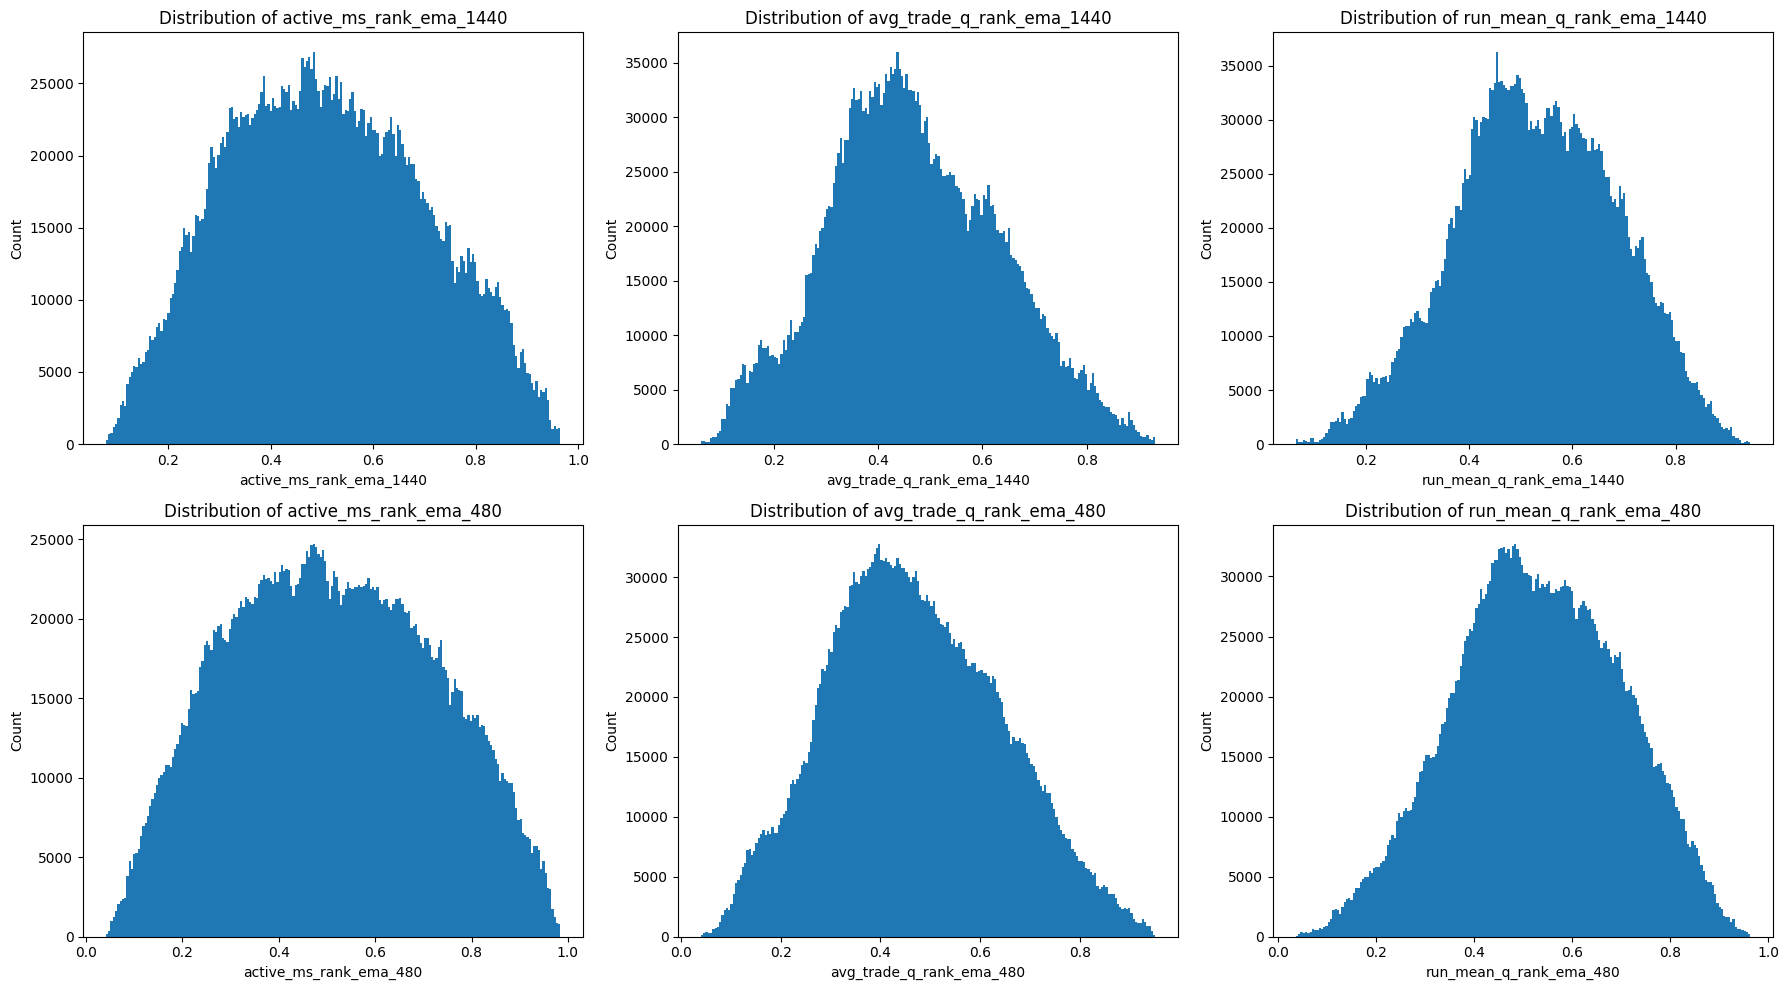

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols = [
    "active_ms_rank_ema_1440",
    "avg_trade_q_rank_ema_1440",
    "run_mean_q_rank_ema_1440",
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()

    ax.set_title(f"Distribution of {c}")
    ax.hist(data, bins=200)
    ax.set_xlabel(c)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

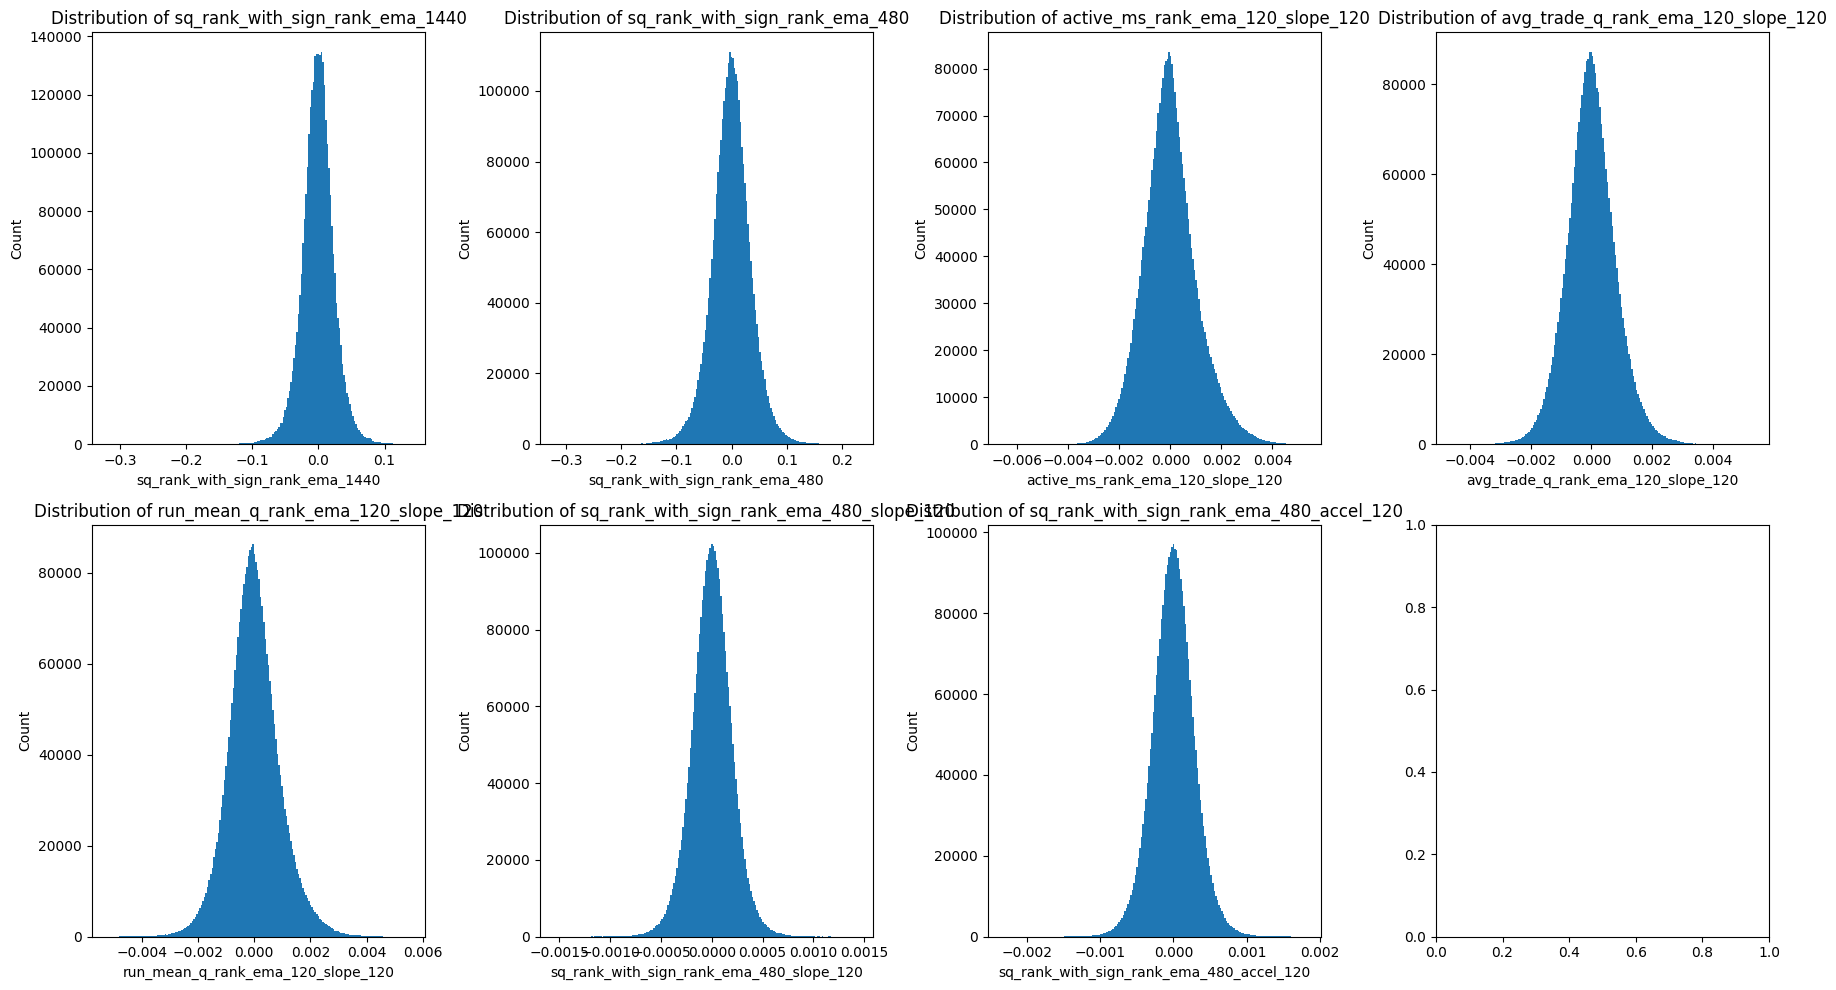

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cols = [
    "sq_rank_with_sign_rank_ema_1440",
    "sq_rank_with_sign_rank_ema_480",
    "active_ms_rank_ema_120_slope_120",
    "avg_trade_q_rank_ema_120_slope_120",
    "run_mean_q_rank_ema_120_slope_120",
    "sq_rank_with_sign_rank_ema_480_slope_120",
    "sq_rank_with_sign_rank_ema_480_accel_120"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for ax, c in zip(axes, cols):
    data = df.select(c).to_series().drop_nulls().to_numpy()

    ax.set_title(f"Distribution of {c}")
    ax.hist(data, bins=200)
    ax.set_xlabel(c)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

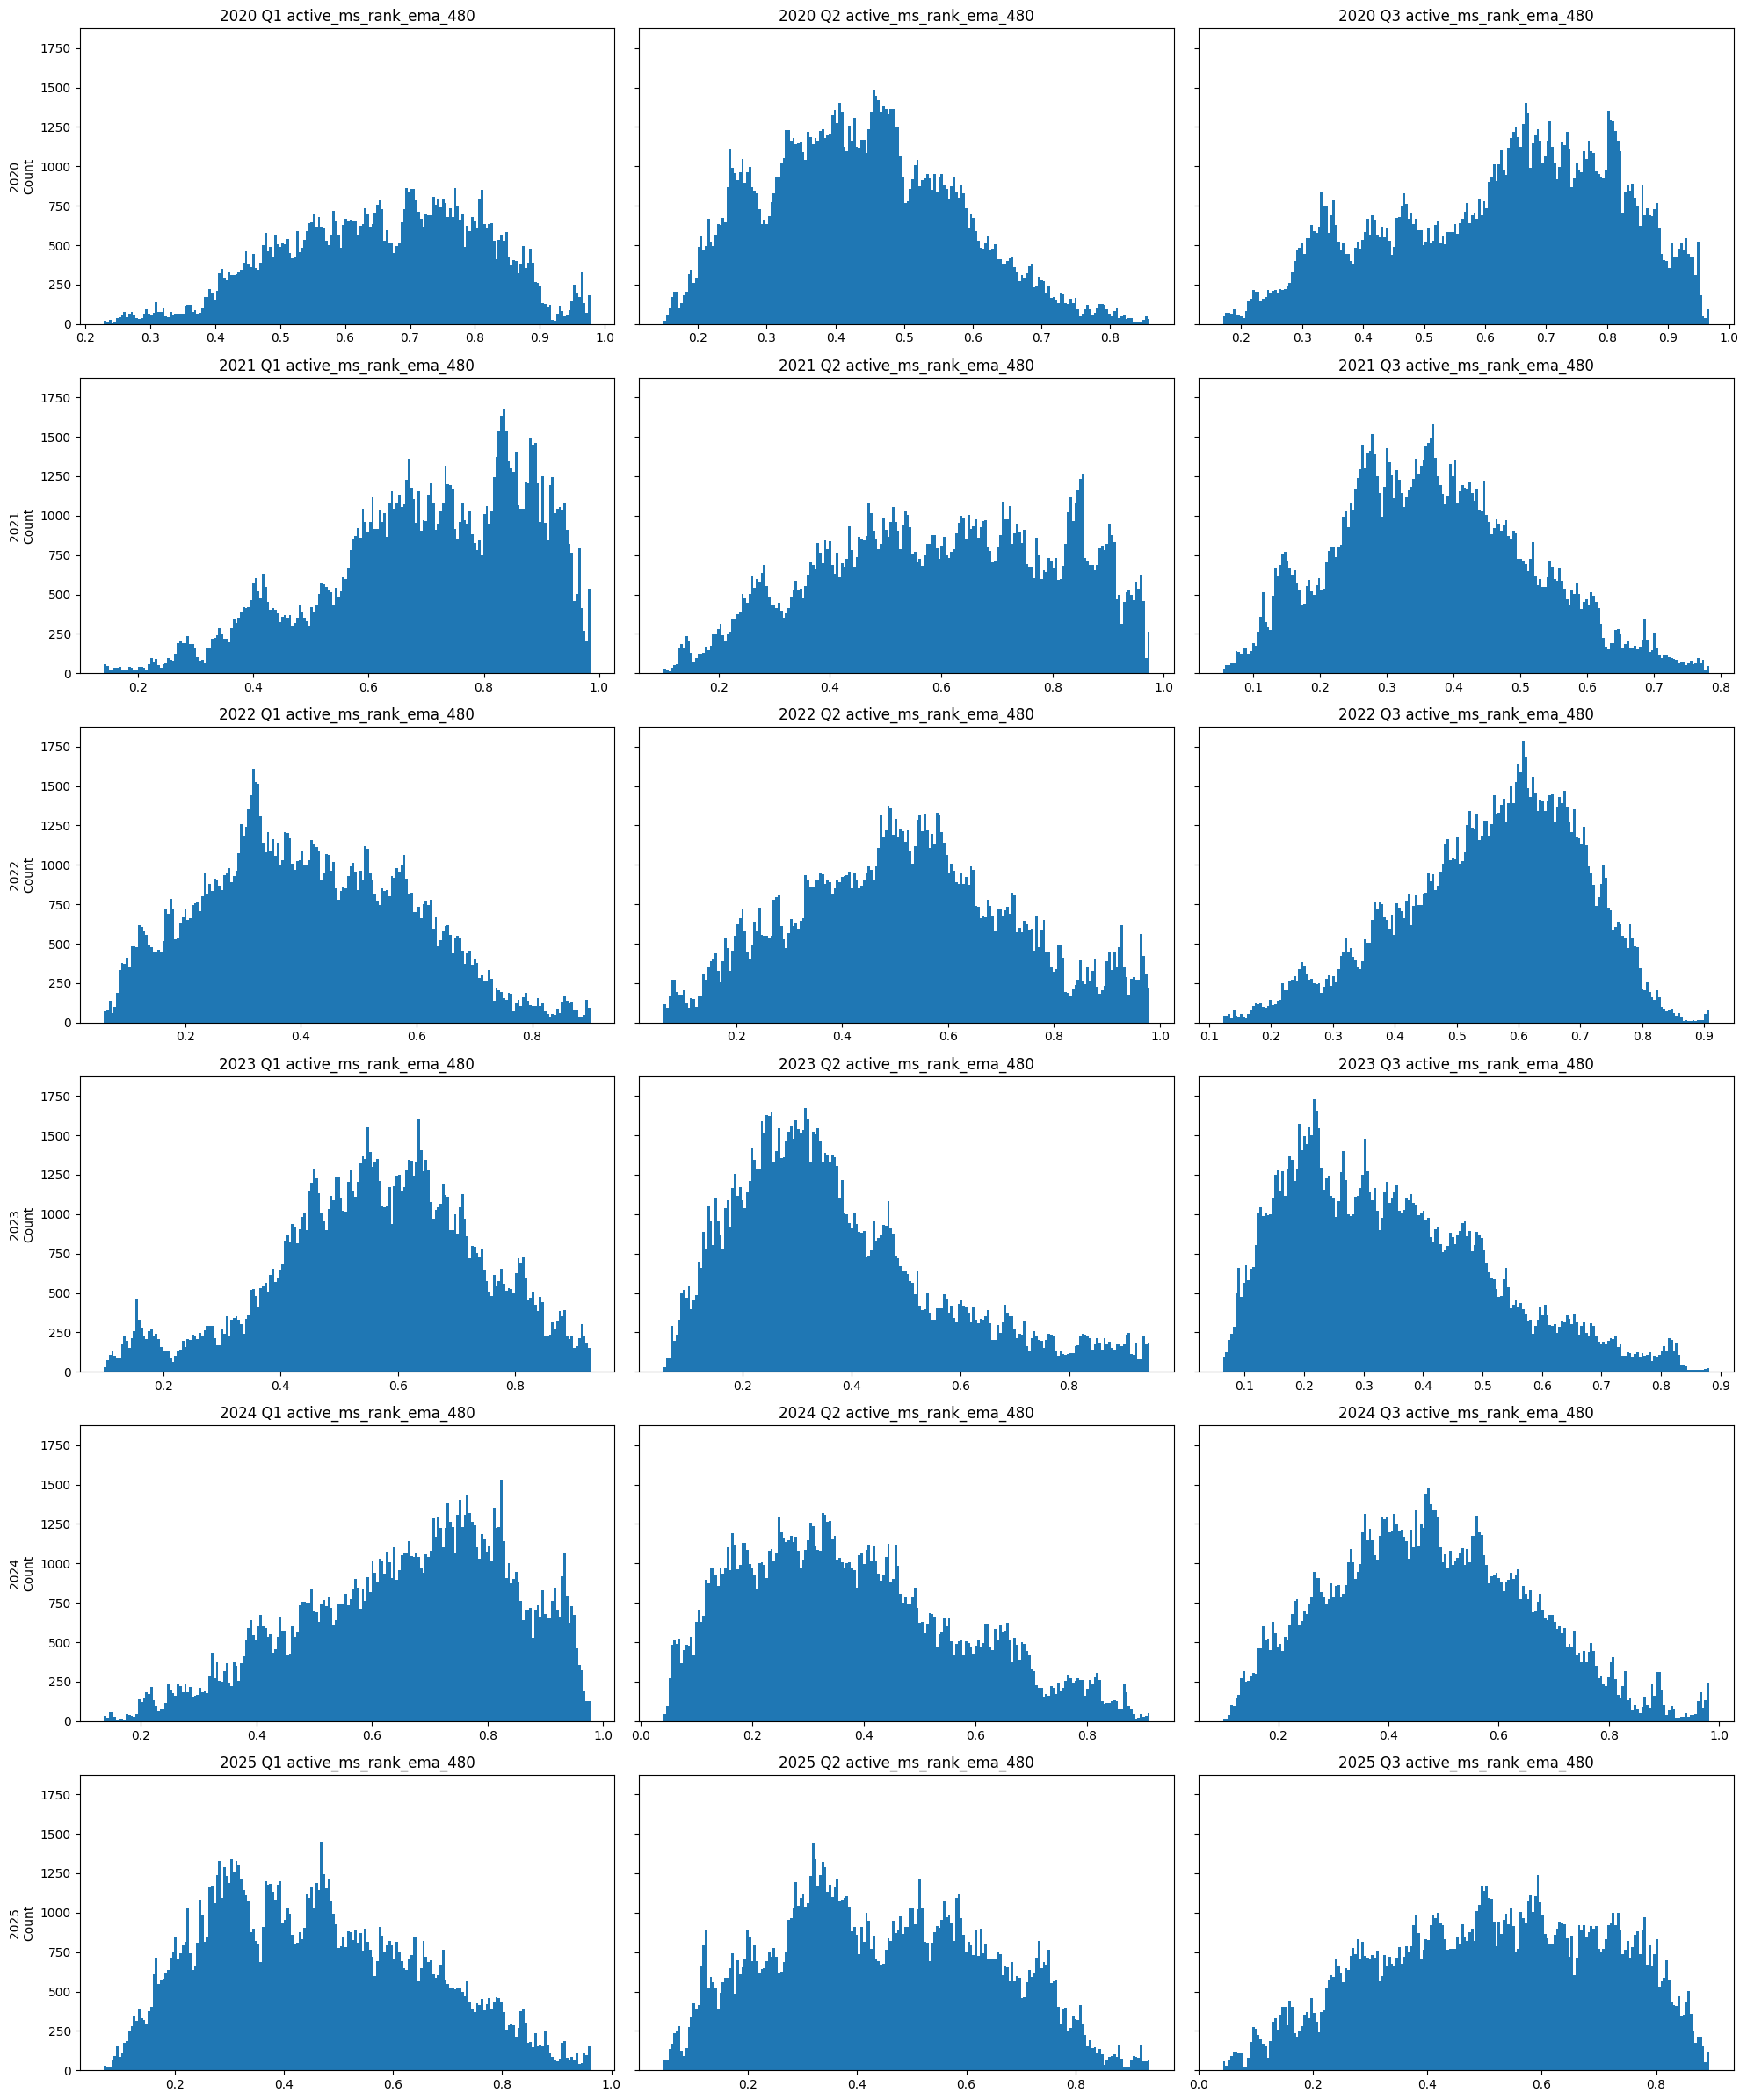

In [ ]:
import matplotlib.pyplot as plt
import polars as pl

years = [2020, 2021, 2022, 2023, 2024, 2025]
quarters = [1, 2, 3]

col = "active_ms_rank_ema_480"

fig, axes = plt.subplots(
    len(years), len(quarters),
    figsize=(20, 4 * len(years)),
    sharey=True,
    sharex=False  # สำคัญ: ให้แต่ละ subplot มีแกน X ของตัวเอง
)

for i, y in enumerate(years):
    for j, q in enumerate(quarters):

        ax = axes[i, j]

        df_yq = df.filter(
            (pl.col("t").dt.year() == y) &
            (pl.col("t").dt.quarter() == q)
        )

        if df_yq.height == 0:
            ax.set_visible(False)
            continue

        # ตัด outlier ด้วย p95 เหมือนเดิม
        # p95 = df_yq.select(pl.col(col).quantile(0.95)).item()
        # p05 = df_yq.select(pl.col(col).quantile(0.05)).item()

        s = (
            df_yq
            # .filter(pl.col(col) <= p95)
            # .filter(pl.col(col) >= p05)
            .select(col)
            .drop_nulls()
            .to_series()
        )

        if s.len() == 0:
            ax.set_visible(False)
            continue

        data = s.to_numpy()

        # ปรับสเกลแกน X ให้เหมาะกับข้อมูลใน subplot นี้
        # ใช้ q01-q99 เพื่อกันหางสุด ๆ ทำให้ zoom ดู shape ชัดขึ้น
        # x_lo = s.quantile(0.01)
        # x_hi = s.quantile(0.99)

        # # เผื่อกรณีข้อมูลแคบมาก/ค่าคงที่
        # if x_lo == x_hi:
        #     pad = 1e-9 if x_lo == 0 else abs(x_lo) * 0.01
        #     x_lo -= pad
        #     x_hi += pad
        # else:
        #     pad = (x_hi - x_lo) * 0.05
        #     x_lo -= pad
        #     x_hi += pad

        ax.hist(data, bins=200)
        # ax.set_xlim(float(x_lo), float(x_hi))
        ax.set_title(f"{y} Q{q} {col}")

        # ให้ทุก subplot โชว์ตัวเลขแกน X ของตัวเอง
        ax.tick_params(axis="x", labelbottom=True)

    axes[i, 0].set_ylabel(f"{y}\nCount")

plt.tight_layout()
plt.show()

### Rolling Corr.

In [ ]:
df = df.with_columns(
    (pl.col("sq_rank_with_sign_rank_ema_1440").abs()).alias("sq_rank_with_sign_rank_ema_1440_abs"),
)

In [ ]:
cols = [
    # "active_ms_rank_ema_1440",
    # "avg_trade_q_rank_ema_1440",
    # "run_mean_q_rank_ema_1440",
    # "sq_rank_with_sign_rank_ema_1440_abs",

    "active_ms_rank_ema_120_slope_120",
    "avg_trade_q_rank_ema_120_slope_120",
    "run_mean_q_rank_ema_120_slope_120",
    "sq_rank_with_sign_rank_ema_480_slope_120"

]

In [ ]:
df_pd = df.select(["t"]+cols).to_pandas()

In [ ]:
BAR_SECONDS = 60   # <- ปรับตามจริง (60 ถ้า 1 นาที, 300 ถ้า 5 นาที, ฯลฯ)
DAYS = 7
WINDOW = int(DAYS * 24 * 3600 / BAR_SECONDS)
MINP = int(WINDOW * 0.6)  # แนะนำ 60% เพื่อกัน missing

print("WINDOW bars =", WINDOW, "min_periods =", MINP)


cols_mat = sorted(set(cols))

rc_mat = rolling_corr_matrix(
    df=df_pd,
    cols=cols_mat,
    window=WINDOW,
    min_periods=MINP,
)


vars_ = cols_mat
pairs = []
scores = []

for i in range(len(vars_)):
    for j in range(i + 1, len(vars_)):
        a, b = vars_[i], vars_[j]
        s = rc_mat[(a, b)].dropna()

        if len(s) < 10:
            continue

        # score option A: คู่ที่ "สัมพันธ์จริง" ใน macro
        score = s.abs().mean()

        pairs.append((a, b))
        scores.append(score)

WINDOW bars = 10080 min_periods = 6048


In [ ]:
pairs

[('active_ms_rank_ema_120_slope_120', 'avg_trade_q_rank_ema_120_slope_120'),
 ('active_ms_rank_ema_120_slope_120', 'run_mean_q_rank_ema_120_slope_120'),
 ('active_ms_rank_ema_120_slope_120',
  'sq_rank_with_sign_rank_ema_480_slope_120'),
 ('avg_trade_q_rank_ema_120_slope_120', 'run_mean_q_rank_ema_120_slope_120'),
 ('avg_trade_q_rank_ema_120_slope_120',
  'sq_rank_with_sign_rank_ema_480_slope_120'),
 ('run_mean_q_rank_ema_120_slope_120',
  'sq_rank_with_sign_rank_ema_480_slope_120')]

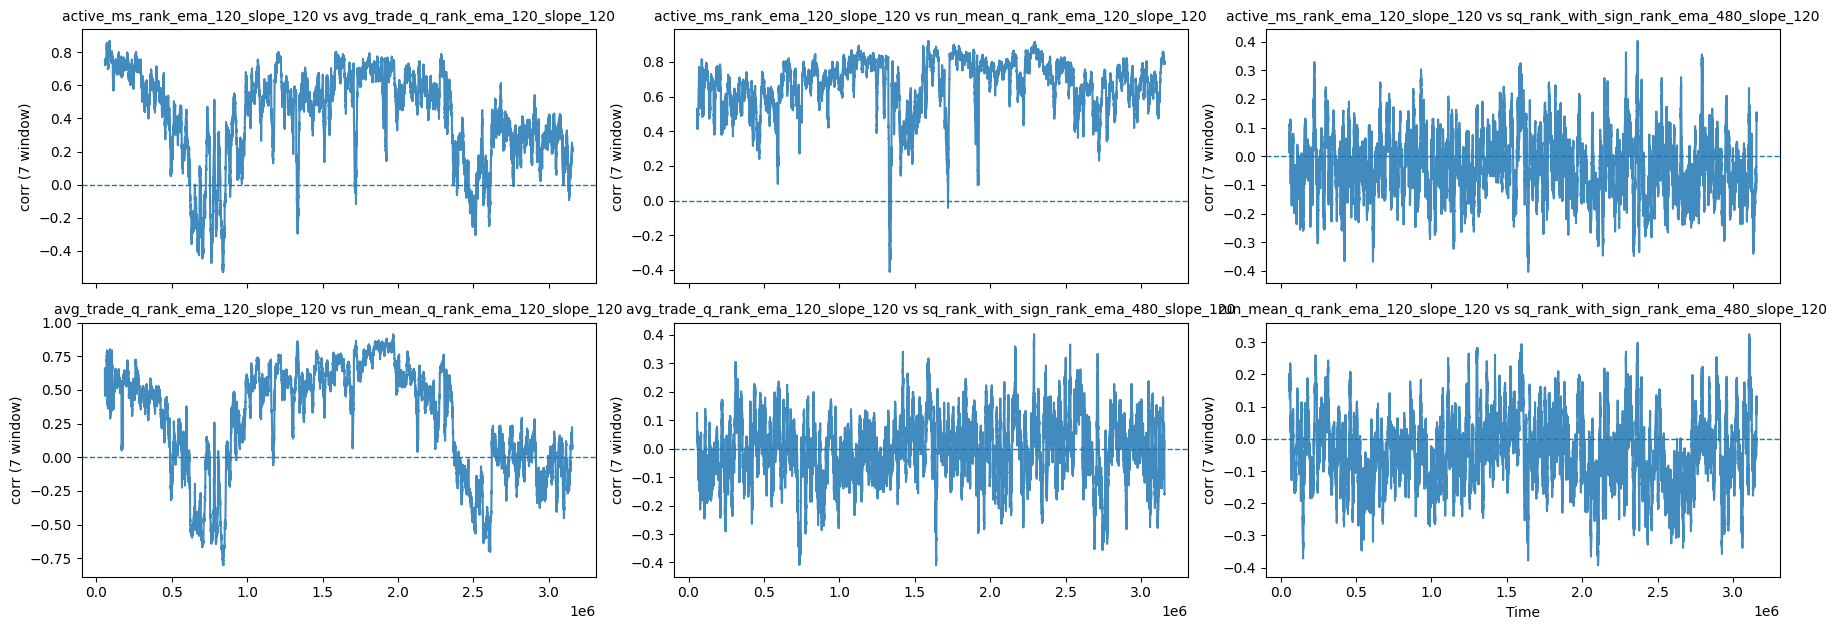

In [ ]:
import numpy as np

n = len(pairs)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 3.2 * nrows),
    sharex=True
)

axes = np.array(axes).reshape(-1)

for idx, (a, b) in enumerate(pairs):
    ax = axes[idx]
    s = rc_mat[(a, b)]

    ax.plot(rc_mat.index, s, alpha=0.85)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"{a} vs {b}", fontsize=10)
    ax.set_ylabel(f"corr ({DAYS} window)")

# ปิดแกนที่เหลือถ้า subplot เกิน
for k in range(n, len(axes)):
    axes[k].axis("off")

axes[min(n-1, len(axes)-1)].set_xlabel("Time")
plt.tight_layout()
plt.show()

## EDA Result

Climate (ช้า, state)
- active_ms_rank_ema_1440
- avg_trade_q_rank_ema_1440
- run_mean_q_rank_ema_1440
- & 480 = Faster Climate

Weather (กลาง, direction of change)
- active_ms_rank_ema_120_slope_120
- avg_trade_q_rank_ema_120_slope_120
- run_mean_q_rank_ema_120_slope_120

Flow (overlay, conditional)
- sq_rank_with_sign_rank_ema_480
- sq_rank_with_sign_rank_ema_480_slope_120
- sq_rank_with_sign_rank_ema_480_accel_120

## Bin 3 Climate Feature

In [ ]:
import polars as pl

def compute_quantile_thresholds(
    df: pl.DataFrame,
    col: str,
    *,
    qs=(0.2, 0.4, 0.6, 0.8),
) -> list[float]:
    s = pl.col(col).cast(pl.Float64)

    # คำนวณทีละ quantile เพื่อให้ได้ scalar float แน่นอน
    vals = []
    for q in qs:
        v = (
            df
            .select(s.drop_nulls().quantile(q).alias("q"))
            .item()
        )
        vals.append(float(v))
    return vals


def add_quantile_bins(
    df: pl.DataFrame,
    col: str,
    *,
    qs=(0.2, 0.4, 0.6, 0.8),
    out_col: str | None = None,
    null_bin: int | None = None,   # เช่น -1 ถ้าอยาก mark null เป็น bin พิเศษ
) -> tuple[pl.DataFrame, list[float]]:
    """
    เพิ่มคอลัมน์ bin 0..len(qs) ตาม quantile thresholds (คำนวณจากทั้ง df)
    คืน df ใหม่ + thresholds ที่ใช้
    """
    if out_col is None:
        out_col = f"{col}_bin"

    thr = compute_quantile_thresholds(df, col, qs=qs)

    x = pl.col(col).cast(pl.Float64)

    expr = pl.when(x.is_null())
    if null_bin is None:
        expr = expr.then(None)  # ให้ null คงเป็น null
    else:
        expr = expr.then(null_bin)

    # ต่อด้วย logic bin ปกติ
    expr = expr.otherwise(
        pl.when(x <= thr[0]).then(0)
        .when(x <= thr[1]).then(1)
        .when(x <= thr[2]).then(2)
        .when(x <= thr[3]).then(3)
        .otherwise(4)
    )

    return df.with_columns(expr.alias(out_col)), thr

In [ ]:
climate_cols = [
    "active_ms_rank_ema_480",
    "avg_trade_q_rank_ema_480",
    "run_mean_q_rank_ema_480",
]

df_bin = df
thresholds = {}

for c in climate_cols:
    df_bin, thr = add_quantile_bins(df_bin, c, qs=(0.2,0.4,0.6,0.8), null_bin=None)
    thresholds[c] = thr

In [ ]:
thresholds

{'active_ms_rank_ema_480': [0.30722719175190394,
  0.4408663702080153,
  0.5691519120419062,
  0.7106522341421708],
 'avg_trade_q_rank_ema_480': [0.31778152203894455,
  0.41201322128916684,
  0.5069174717138872,
  0.6252692230087683],
 'run_mean_q_rank_ema_480': [0.383221223700736,
  0.48097227388861485,
  0.5771099669961096,
  0.6851278665730811]}

In [ ]:
import polars as pl

def confirm_after_x(
    df: pl.DataFrame,
    *,
    col: str,
    x_bars: int,
    t_col: str = "t",
    out_col: str | None = None,
) -> pl.DataFrame:
    """
    Confirm-after-X for categorical states.
    Accept a new value only if it persists for >= x_bars bars.
    Otherwise hold the previous confirmed value.
    """
    out_col = out_col or f"{col}_c{x_bars}"

    d = df.sort(t_col)

    # run id on RAW column
    run_id = (
        (pl.col(col) != pl.col(col).shift(1))
        .cast(pl.Int8)
        .fill_null(0)
        .cum_sum()
        .alias("__run_id")
    )

    # compute run length + run value
    tmp = (
        d.select([t_col, col])
         .with_columns(run_id)
         .with_columns([
             pl.len().over("__run_id").alias("__run_len"),
             pl.first(col).over("__run_id").alias("__run_val"),
         ])
         # candidate only if run_len >= x_bars
         .with_columns(
             pl.when(pl.col("__run_len") >= x_bars)
               .then(pl.col("__run_val"))
               .otherwise(None)
               .alias("__candidate")
         )
         .select([t_col, "__candidate"])
    )

    # forward-fill last confirmed candidate
    return (
        d.join(tmp, on=t_col, how="left")
         .with_columns(pl.col("__candidate").forward_fill().alias(out_col))
         .drop("__candidate")
    )

In [ ]:
CONFIRM_X_FINAL = {
    "active_ms_rank_ema_480_bin": 30,
    "avg_trade_q_rank_ema_480_bin": 30,
    "run_mean_q_rank_ema_480_bin": 30,
}

df_bin = confirm_after_x(
    df_bin,
    col="active_ms_rank_ema_480_bin",
    x_bars=CONFIRM_X_FINAL["active_ms_rank_ema_480_bin"],
    out_col="active_ms_rank_ema_480_bin_c",
)

df_bin = confirm_after_x(
    df_bin,
    col="avg_trade_q_rank_ema_480_bin",
    x_bars=CONFIRM_X_FINAL["avg_trade_q_rank_ema_480_bin"],
    out_col="avg_trade_q_rank_ema_480_bin_c",
)

df_bin = confirm_after_x(
    df_bin,
    col="run_mean_q_rank_ema_480_bin",
    x_bars=CONFIRM_X_FINAL["run_mean_q_rank_ema_480_bin"],
    out_col="run_mean_q_rank_ema_480_bin_c",
)

In [ ]:
df_bin = df_bin.with_columns(
    (
        pl.col("active_ms_rank_ema_480_bin_c").cast(pl.Utf8) + "_" +
        pl.col("avg_trade_q_rank_ema_480_bin_c").cast(pl.Utf8) + "_" +
        pl.col("run_mean_q_rank_ema_480_bin_c").cast(pl.Utf8)
    ).alias("climate_state")
)

In [ ]:
df_bin.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'avg_trade_q_rank_like_Lint',
 'avg_trade_q_rank_ema_30',
 'avg_trade_q_rank_ema_120',
 'avg_trade_q_rank_ema_480',
 'avg_trade_q_rank_ema_1440',
 'avg_trade_q_rank_ema_120_slope_30',
 'avg_trade_q_rank_ema_120_slope_120',
 'avg_trade_q_thr_hi_Lint',
 'avg_trade_q_evt',
 'avg_trade_q_sev',
 'avg_trade_q_evt_frac_60m',
 'avg_trade_q_evt_frac_240m',
 'run_mean_q_rank_like_Lint',
 'run_mean_q_rank_ema_30',
 'run_mean_q_rank_ema_120',
 'run_mean_q_rank_ema_480',
 'run_mean_q_rank_ema_1440',
 'run_mean_q_rank_ema_120_slope_30',
 'run_m

## EDA Bin

In [ ]:
def _ensure_sorted(df: pl.DataFrame, t_col: str) -> pl.DataFrame:
    return df.sort(t_col)


def add_regime_core_memory(
    df: pl.DataFrame,
    *,
    regime_col: str = "volac_regime",
    t_col: str = "t",
    out_prev: str = "prev_regime",
    out_change: str = "regime_change",
    out_run_id: str = "regime_run_id",
    out_time_in: str = "time_in_regime_bars",
    out_first: str = "is_first_entry",
) -> pl.DataFrame:
    """
    Adds:
      - prev_regime: previous bar regime
      - regime_change: 1 if regime changes at t
      - regime_run_id: contiguous segment id
      - time_in_regime_bars: 1..run_len within each segment
      - is_first_entry: 1 at first bar of each segment else 0
    """
    d = _ensure_sorted(df, t_col)

    return (
        d.with_columns([
            pl.col(regime_col).shift(1).alias(out_prev),
            (pl.col(regime_col) != pl.col(regime_col).shift(1))
                .cast(pl.UInt8)
                .fill_null(0)
                .alias(out_change),
        ])
        .with_columns([
            pl.col(out_change).cum_sum().alias(out_run_id),
        ])
        .with_columns([
            # 1..N inside each run
            pl.int_range(1, pl.len() + 1).over(out_run_id).alias(out_time_in),
            (pl.int_range(1, pl.len() + 1).over(out_run_id) == 1)
                .cast(pl.UInt8)
                .alias(out_first),
        ])
    )

def transition_table(
    df: pl.DataFrame,
    *,
    regime_col: str = "volac_regime",
    t_col: str = "t",
    min_count: int = 1,
) -> pl.DataFrame:
    """
    Returns long-form transition table:
      from_regime, to_regime, n, p(to|from)

    Counts only actual changes (from != to), ignores nulls.
    """
    d = _ensure_sorted(df, t_col).select([regime_col])

    trans = (
        d.with_columns([
            pl.col(regime_col).shift(1).alias("from_regime"),
            pl.col(regime_col).alias("to_regime"),
        ])
        .filter(
            pl.col("from_regime").is_not_null()
            & pl.col("to_regime").is_not_null()
            & (pl.col("from_regime") != pl.col("to_regime"))
        )
        .group_by(["from_regime", "to_regime"])
        .agg(pl.len().alias("n"))
        .filter(pl.col("n") >= min_count)
    )

    # normalize to probabilities by from_regime
    return (
        trans.with_columns(
            (pl.col("n") / pl.col("n").sum().over("from_regime")).alias("p")
        )
        .sort(["from_regime", "p"], descending=[False, True])
    )


def transition_matrix_wide(
    df: pl.DataFrame,
    *,
    regime_col: str = "volac_regime",
    t_col: str = "t",
    value: str = "p",  # "p" or "n"
    min_count: int = 1,
) -> pl.DataFrame:
    """
    Wide matrix: rows=from_regime, cols=to_regime, values=p or n
    """
    tt = transition_table(df, regime_col=regime_col, t_col=t_col, min_count=min_count)
    val_col = value if value in ("p", "n") else "p"
    return (
        tt.pivot(
            values=val_col,
            index="from_regime",
            columns="to_regime",
            aggregate_function="first",
        )
        .fill_null(0)
    )

def regime_runlengths(
    df: pl.DataFrame,
    *,
    regime_col: str = "volac_regime",
    t_col: str = "t",
    bar_minutes: int = 1,
) -> pl.DataFrame:
    """
    Per-regime run length stats: n_runs, mean, p50, p90, p99, max (in bars + minutes).
    """
    d = _ensure_sorted(df, t_col).select([t_col, regime_col])

    run_id = (
        (pl.col(regime_col) != pl.col(regime_col).shift(1))
        .cast(pl.Int8)
        .fill_null(0)
        .cum_sum()
        .alias("__rid")
    )

    runs = (
        d.with_columns(run_id)
         .group_by("__rid")
         .agg([
             pl.first(regime_col).alias("regime"),
             pl.len().alias("run_len_bars"),
         ])
         .drop("__rid")
    )

    return (
        runs.group_by("regime")
            .agg([
                pl.len().alias("n_runs"),
                pl.col("run_len_bars").mean().alias("mean_bars"),
                pl.col("run_len_bars").quantile(0.50).alias("p50_bars"),
                pl.col("run_len_bars").quantile(0.90).alias("p90_bars"),
                pl.col("run_len_bars").quantile(0.99).alias("p99_bars"),
                pl.col("run_len_bars").max().alias("max_bars"),
            ])
            .with_columns([
                (pl.col("mean_bars") * bar_minutes).alias("mean_minutes"),
                (pl.col("p50_bars") * bar_minutes).alias("p50_minutes"),
                (pl.col("p90_bars") * bar_minutes).alias("p90_minutes"),
                (pl.col("p99_bars") * bar_minutes).alias("p99_minutes"),
                (pl.col("max_bars") * bar_minutes).alias("max_minutes"),
            ])
            .sort("n_runs", descending=True)
    )

In [ ]:
dfm = add_regime_core_memory(df_bin.select([
    "t","close", "climate_state"
]), regime_col="climate_state", t_col="t")

In [ ]:
dfm

t,close,climate_state,prev_regime,regime_change,regime_run_id,time_in_regime_bars,is_first_entry
datetime[ms],f64,str,str,u8,i64,i64,u8
2020-01-01 00:00:00,129.02,null,null,0,0,1,1
2020-01-01 00:01:00,129.02,null,null,0,0,2,0
2020-01-01 00:02:00,128.98,null,null,0,0,3,0
2020-01-01 00:03:00,128.98,null,null,0,0,4,0
2020-01-01 00:04:00,128.88,null,null,0,0,5,0
…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.82,"""0_3_1""","""0_3_1""",0,10574,515,0
2025-12-31 23:56:00,2972.82,"""0_3_1""","""0_3_1""",0,10574,516,0
2025-12-31 23:57:00,2971.64,"""0_3_1""","""0_3_1""",0,10574,517,0


In [ ]:
tt = transition_table(dfm, regime_col="climate_state", t_col="t", min_count=20)
tm_p = transition_matrix_wide(dfm, regime_col="climate_state", t_col="t", value="p", min_count=20)

/tmp/ipython-input-3474514207.py:99: DeprecationWarning:

the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.



In [ ]:
tt_pandas = tt.to_pandas()

In [ ]:
tt_pandas["from_regime"].unique()

array(['0_0_0', '0_0_1', '0_1_0', '0_1_1', '0_1_2', '0_2_0', '0_2_1',
       '0_2_2', '0_3_0', '0_3_1', '0_3_2', '0_4_0', '0_4_1', '0_4_2',
       '1_0_0', '1_0_1', '1_1_0', '1_1_1', '1_1_2', '1_1_3', '1_1_4',
       '1_2_0', '1_2_1', '1_2_2', '1_2_3', '1_3_0', '1_3_1', '1_3_2',
       '1_3_3', '1_4_0', '1_4_1', '1_4_2', '1_4_3', '2_0_0', '2_0_1',
       '2_0_2', '2_0_3', '2_0_4', '2_1_1', '2_1_2', '2_1_3', '2_1_4',
       '2_2_1', '2_2_2', '2_2_3', '2_2_4', '2_3_1', '2_3_2', '2_3_3',
       '2_4_0', '2_4_1', '2_4_2', '2_4_3', '3_0_1', '3_0_2', '3_0_3',
       '3_0_4', '3_1_2', '3_1_3', '3_1_4', '3_2_1', '3_2_2', '3_2_3',
       '3_2_4', '3_3_2', '3_3_3', '3_3_4', '3_4_0', '3_4_1', '3_4_2',
       '3_4_3', '3_4_4', '4_0_1', '4_0_2', '4_0_3', '4_0_4', '4_1_3',
       '4_1_4', '4_2_3', '4_2_4', '4_3_3', '4_3_4', '4_4_3', '4_4_4'],
      dtype=object)

In [ ]:
tt_pandas[tt_pandas["from_regime"] == "0_0_0"]

,from_regime,to_regime,n,p
0,0_0_0,0_1_0,60,0.566038
1,0_0_0,0_0_1,23,0.216981
2,0_0_0,1_0_0,23,0.216981


In [ ]:
rl = regime_runlengths(dfm, regime_col="climate_state", t_col="t")

In [ ]:
rl

regime,n_runs,mean_bars,p50_bars,p90_bars,p99_bars,max_bars,mean_minutes,p50_minutes,p90_minutes,p99_minutes,max_minutes
str,u32,f64,f64,f64,f64,u32,f64,f64,f64,f64,u32
"""0_2_0""",200,430.775,283.0,921.0,2093.0,3486,430.775,283.0,921.0,2093.0,3486
"""1_3_1""",195,222.471795,153.0,506.0,796.0,1110,222.471795,153.0,506.0,796.0,1110
"""3_2_3""",192,243.880208,173.0,567.0,1001.0,2320,243.880208,173.0,567.0,1001.0,2320
"""3_3_3""",191,258.109948,147.0,625.0,1458.0,2046,258.109948,147.0,625.0,1458.0,2046
"""1_2_2""",187,198.229947,134.0,462.0,775.0,846,198.229947,134.0,462.0,775.0,846
…,…,…,…,…,…,…,…,…,…,…,…
"""1_3_4""",9,261.0,238.0,461.0,733.0,733,261.0,238.0,461.0,733.0,733
"""4_3_0""",8,131.0,140.0,227.0,321.0,321,131.0,140.0,227.0,321.0,321
"""4_1_0""",8,429.25,370.0,757.0,820.0,820,429.25,370.0,757.0,820.0,820


In [ ]:
rl.write_csv("Activity_avgTradeQuote_RunMean_climate_state_1440min.csv")

In [ ]:
from typing import Iterable

def add_forward_returns(
    df: pl.DataFrame,
    *,
    price_col: str = "close",
    horizons: Iterable[int] = (15, 60),  # minutes for 1m bars
    out_prefix: str = "fwd_ret_",
) -> pl.DataFrame:
    """
    Adds forward log returns for given horizons (in bars/minutes).
      fwd_ret_H = log(close[t+H]/close[t])
    """
    d = df
    exprs = []
    for h in horizons:
        exprs.append(
            (pl.col(price_col).shift(-h) / pl.col(price_col)).log().alias(f"{out_prefix}{h}m")
        )
    return d.with_columns(exprs)

def add_forward_realized_vol(
    df: pl.DataFrame,
    *,
    price_col: str = "close",
    horizon: int = 60,            # future window length in bars
    out_col: str = "fwd_rvol_60m",
) -> pl.DataFrame:
    """
    Adds forward realized volatility proxy over next `horizon` bars:
      sqrt(sum_{i=1..H} r_{t+i}^2)
    using 1-bar log returns.
    """
    r1 = (pl.col(price_col) / pl.col(price_col).shift(1)).log().alias("__r1")
    d = df.with_columns(r1)

    # future sum of squares: shift(-1) to start from next bar
    return (
        d.with_columns(
            pl.col("__r1").shift(-1).pow(2).rolling_sum(window_size=horizon).sqrt().alias(out_col)
        )
        .drop("__r1")
    )

def regime_outcome_summary(
    df: pl.DataFrame,
    *,
    regime_col: str = "volac_regime",
    outcome_cols: Iterable[str] = ("fwd_ret_5m", "fwd_ret_15m", "fwd_ret_60m"),
    min_n: int = 500,
) -> pl.DataFrame:
    """
    For each regime, summarize outcome distributions (mean, median, p10, p90, n).
    Filters regimes with n >= min_n.
    """
    aggs = []
    for c in outcome_cols:
        aggs += [
            pl.col(c).count().alias(f"{c}__n"),
            pl.col(c).mean().alias(f"{c}__mean"),
            pl.col(c).quantile(0.50).alias(f"{c}__p50"),
            pl.col(c).quantile(0.10).alias(f"{c}__p10"),
            pl.col(c).quantile(0.90).alias(f"{c}__p90"),
        ]

    out = (
        df.group_by(regime_col)
          .agg(aggs)
          .with_columns(pl.min_horizontal([pl.col(f"{c}__n") for c in outcome_cols]).alias("n_min"))
          .filter(pl.col("n_min") >= min_n)
          .drop("n_min")
          .sort(regime_col)
    )
    return out

In [ ]:
dfo = add_forward_returns(dfm, price_col="close", horizons=(15,60))
dfo = add_forward_realized_vol(dfo, price_col="close", horizon=60, out_col="fwd_rvol_60m")
summ = regime_outcome_summary(
    dfo,
    regime_col="climate_state",
    outcome_cols=("fwd_ret_60m", "fwd_rvol_60m"),
    min_n=5000,
)

In [ ]:
summ

climate_state,fwd_ret_60m__n,fwd_ret_60m__mean,fwd_ret_60m__p50,fwd_ret_60m__p10,fwd_ret_60m__p90,fwd_rvol_60m__n,fwd_rvol_60m__mean,fwd_rvol_60m__p50,fwd_rvol_60m__p10,fwd_rvol_60m__p90
str,u32,f64,f64,f64,f64,u32,f64,f64,f64,f64
null,50872,0.000462,0.000314,-0.00687,0.007984,50813,0.006902,0.006015,0.003781,0.010751
"""0_0_0""",71300,0.000099,0.000038,-0.003411,0.003607,71277,0.002995,0.002365,0.000958,0.005778
"""0_0_1""",26271,-0.000307,-0.000129,-0.005116,0.004556,26271,0.004527,0.003964,0.002148,0.007297
"""0_0_2""",3943,0.000636,0.000029,-0.003935,0.00627,3943,0.004051,0.003134,0.002058,0.007097
"""0_0_3""",3092,0.000159,0.00031,-0.004608,0.004819,3092,0.003573,0.003194,0.002108,0.005979
…,…,…,…,…,…,…,…,…,…,…
"""4_4_0""",7696,0.000609,0.000527,-0.013732,0.015216,7696,0.012294,0.010867,0.005516,0.021086
"""4_4_1""",7393,0.000901,0.000984,-0.010048,0.015005,7393,0.011891,0.009279,0.004346,0.019707
"""4_4_2""",18194,0.001448,0.001096,-0.011002,0.01449,18194,0.011896,0.00997,0.004863,0.020812


In [ ]:
summ.write_csv("Activity_avgTradeQuote_RunMean_climate_state_1440min_fwd_ret_fwd_rvol.csv")

In [ ]:
dfm

t,close,climate_state,prev_regime,regime_change,regime_run_id,time_in_regime_bars,is_first_entry
datetime[ms],f64,str,str,u8,i64,i64,u8
2020-01-01 00:00:00,129.02,null,null,0,0,1,1
2020-01-01 00:01:00,129.02,null,null,0,0,2,0
2020-01-01 00:02:00,128.98,null,null,0,0,3,0
2020-01-01 00:03:00,128.98,null,null,0,0,4,0
2020-01-01 00:04:00,128.88,null,null,0,0,5,0
…,…,…,…,…,…,…,…
2025-12-31 23:55:00,2971.82,"""0_3_1""","""0_3_1""",0,10574,515,0
2025-12-31 23:56:00,2972.82,"""0_3_1""","""0_3_1""",0,10574,516,0
2025-12-31 23:57:00,2971.64,"""0_3_1""","""0_3_1""",0,10574,517,0


In [ ]:
bin = df_bin.select([
    't',
    'avg_trade_q_rank_ema_480_bin',
    'run_mean_q_rank_ema_480_bin',
    'active_ms_rank_ema_480_bin_c',
    'avg_trade_q_rank_ema_480_bin_c',
    'run_mean_q_rank_ema_480_bin_c',
    'climate_state'
])

In [ ]:
merged = data.join(
    bin,
    on='t',
    how='left'
)

In [ ]:
merged.write_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_climate_state_480.parquet")))

## Compute Porto Payoff

In [ ]:
df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_climate_state_480.parquet")))

In [ ]:
df.drop([
 'avg_trade_q_rank_ema_480_bin',
 'run_mean_q_rank_ema_480_bin'
]).columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'signed_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'active_ms',
 'intensity_peak_1s',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_q',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'run_max',
 'run_mean',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'rv_sqrt',
 'flip_rate',
 'active_ms_rank_ema_480_bin_c',
 'avg_trade_q_rank_ema_480_bin_c',
 'run_mean_q_rank_ema_480_bin_c',
 'climate_state']

In [ ]:
H_LIST = [15, 60]          # horizons in bars (ปรับได้)
P_LIST = [0.50, 0.90, 0.95, 0.99]
K_SIG_LIST = [2.0, 3.0]       # tail threshold in sigma
THETA_LIST = [0.001, 0.002]   # opportunity thresholds in abs-return (เช่น 10bp/20bp)
STATE_COL = "climate_state"
RET_BASE = "ret_cc"           # ใช้ ret_cc เป็น base return ของ bar (log/linear ได้ทั้งคู่ แต่ต้อง consistent)
RV_COL = "rv_sqrt" # ใช้ realized var เป็น proxy

In [ ]:
def add_forward_cols(df: pl.DataFrame, H: int) -> pl.DataFrame:
    # forward return over H bars: sum of bar returns (ใช้กับ log-return ได้ดี)
    # ถ้า ret_cc เป็น simple return ก็ยังใช้ sum เป็น approximation (แนะนำ log-return มากกว่า)
    return df.with_columns([
        pl.col(RET_BASE).cast(pl.Float64).rolling_sum(window_size=H).shift(-H).alias(f"ret_fwd_{H}"),
        # forward realized variance over next H bars (sum of per-bar realized_var)
        pl.col(RV_COL).cast(pl.Float64).rolling_sum(window_size=H).shift(-H).alias(f"rv_fwd_{H}"),
        # forward realized volatility (sqrt variance)
        pl.col(RV_COL).cast(pl.Float64).rolling_sum(window_size=H).shift(-H).sqrt().alias(f"rvol_fwd_{H}"),
        # sign of last bar return (for continuation/reversal definition)
        pl.col(RET_BASE).cast(pl.Float64).sign().alias("sign_now"),
        pl.col(RET_BASE).cast(pl.Float64).shift(1).sign().alias("sign_prev"),
    ])

In [ ]:
def compute_proto_payoff_by_state(
    df: pl.DataFrame,
    *,
    state_col: str = STATE_COL,
    h_list: list[int] = H_LIST,
    p_list: list[float] = P_LIST,
    ksig_list: list[float] = K_SIG_LIST,
    theta_list: list[float] = THETA_LIST,
) -> dict[int, pl.DataFrame]:
    df0 = df.sort("t")

    out = {}

    for H in h_list:
        d = add_forward_cols(df0, H)

        ret = pl.col(f"ret_fwd_{H}")
        absret = ret.abs()
        rv = pl.col(f"rv_fwd_{H}")
        rvol = pl.col(f"rvol_fwd_{H}")

        # continuation/reversal:
        # continuation = sign(ret_fwd) == sign(prev bar) AND prev bar != 0
        cont = ((ret.sign() == pl.col("sign_prev")) & (pl.col("sign_prev") != 0)).cast(pl.Int8)
        rev  = ((ret.sign() == -pl.col("sign_prev")) & (pl.col("sign_prev") != 0)).cast(pl.Int8)

        # jump proxy: absret very large relative to rvol
        # (ถ้า rvol เป็น sqrt(var) แล้ว absret/rvol = shockiness)
        shock = (absret / (rvol + 1e-12)).alias(f"shock_{H}")

        # groupby aggregations
        aggs: list[pl.Expr] = [
            pl.len().alias("n"),
            # directionality
            ret.mean().alias(f"mean_ret_{H}"),
            ret.median().alias(f"med_ret_{H}"),
            (ret > 0).mean().alias(f"p_up_{H}"),
            cont.mean().alias(f"p_cont_{H}"),
            rev.mean().alias(f"p_rev_{H}"),
            # movement
            absret.mean().alias(f"mean_absret_{H}"),
            # vol persistence
            rv.mean().alias(f"mean_rv_{H}"),
            rvol.mean().alias(f"mean_rvol_{H}"),
            # liquidity/impact proxy-ish
            shock.mean().alias(f"mean_shock_{H}"),
            (shock > 3.0).mean().alias(f"jump_freq_shock>3_{H}"),
        ]

        # quantiles of absret + ret (optional)
        for p in p_list:
            aggs += [
                absret.quantile(p).alias(f"q{int(p*100):02d}_absret_{H}"),
                ret.quantile(p).alias(f"q{int(p*100):02d}_ret_{H}"),
            ]

        # tail frequency based on k-sigma (sigma computed within state, stable enough for proto)
        # NOTE: this makes it "within-state standardized", good for comparing tails across states
        # We'll compute std inside groupby using a two-pass trick: aggregate std then derive freq using join.
        # Simpler version: use global sigma per state via std in same group, then approx with another pass below.

        # opportunity density: fraction(|ret| > theta)
        for th in theta_list:
            aggs += [(absret > th).mean().alias(f"frac_absret_gt_{th:g}_{H}")]

        g = (
            d.filter(ret.is_not_null() & rvol.is_not_null() & pl.col(state_col).is_not_null())
             .group_by(state_col)
             .agg(aggs)
        )

        # add risk-adjusted + stability proxies (t-stat) + downside
        # need std; compute in a separate agg then join
        g_std = (
            d.filter(ret.is_not_null() & pl.col(state_col).is_not_null())
             .group_by(state_col)
             .agg([
                 ret.std().alias(f"std_ret_{H}"),
                 (pl.when(ret < 0).then(ret).otherwise(0.0)).std().alias(f"std_down_ret_{H}"),
             ])
        )

        g = g.join(g_std, on=state_col, how="left").with_columns([
            (pl.col(f"mean_ret_{H}") / (pl.col(f"std_ret_{H}") + 1e-12)).alias(f"sharpeish_{H}"),
            (pl.col(f"mean_ret_{H}") / ((pl.col(f"std_ret_{H}") + 1e-12) / (pl.col("n").sqrt()))).alias(f"tstat_meanret_{H}"),
            # mean_ret / mean_rvol (เร็วและ practical มาก)
            (pl.col(f"mean_ret_{H}") / (pl.col(f"mean_rvol_{H}") + 1e-12)).alias(f"ret_over_rvol_{H}"),
        ])

        # tail freq using k-sigma within state
        # compute freq(|ret| > k * std_ret_state)
        # (ทำจาก raw d แล้ว groupby โดยใช้ std_ret_{H} ที่ join มา)
        tail_base = (
            d.filter(ret.is_not_null() & pl.col(state_col).is_not_null())
             .group_by(state_col)
             .agg([ret.std().alias(f"std_ret_{H}")])
        )

        d2 = d.join(tail_base, on=state_col, how="left")

        tail_aggs = []
        for k in ksig_list:
            tail_aggs += [
                (absret > (pl.col(f"std_ret_{H}") * k)).mean().alias(f"freq_absret_gt_{k}sigma_{H}")
            ]

        g_tail = d2.group_by(state_col).agg(tail_aggs)

        g = g.join(g_tail, on=state_col, how="left").sort("n", descending=True)

        out[H] = g

    return out

In [ ]:
proto = compute_proto_payoff_by_state(df)

In [ ]:
proto[15]

climate_state,n,mean_ret_15,med_ret_15,p_up_15,p_cont_15,p_rev_15,mean_absret_15,mean_rv_15,mean_rvol_15,mean_shock_15,jump_freq_shock>3_15,q50_absret_15,q50_ret_15,q90_absret_15,q90_ret_15,q95_absret_15,q95_ret_15,q99_absret_15,q99_ret_15,frac_absret_gt_0.001_15,frac_absret_gt_0.002_15,std_ret_15,std_down_ret_15,sharpeish_15,tstat_meanret_15,ret_over_rvol_15,freq_absret_gt_2.0sigma_15,freq_absret_gt_3.0sigma_15
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0_1_0""",85721,-0.000044,-0.000015,0.494628,0.468228,0.481049,0.001286,0.003531,0.053472,0.023032,0.0,0.000845,-0.000015,0.002834,0.001904,0.003944,0.002815,0.007061,0.005291,0.434958,0.185719,0.00204,0.001428,-0.021496,-6.293718,-0.00082,0.0465,0.015655
"""0_0_0""",79642,0.000024,-0.000003,0.498317,0.447556,0.454588,0.001124,0.003781,0.05377,0.019246,0.0,0.000665,-0.000003,0.002573,0.00166,0.003732,0.002641,0.0074,0.005855,0.353419,0.149381,0.001861,0.001152,0.01299,3.66597,0.00045,0.050325,0.020529
"""0_2_0""",76321,0.000043,0.000013,0.504475,0.473395,0.485528,0.001363,0.003405,0.052635,0.024915,0.0,0.000914,0.000013,0.002954,0.002036,0.004094,0.003016,0.007981,0.006412,0.463726,0.198346,0.002099,0.001276,0.020518,5.668414,0.000818,0.047379,0.018972
"""4_4_4""",75794,0.000074,0.000025,0.50256,0.491569,0.503048,0.005448,0.030102,0.143702,0.035875,0.0,0.003348,0.000026,0.012195,0.007969,0.016925,0.012441,0.033112,0.025819,0.827625,0.671966,0.009358,0.005902,0.007951,2.189071,0.000518,0.039607,0.014975
"""4_3_4""",70256,-0.000035,0.000039,0.505352,0.492029,0.502164,0.003616,0.014052,0.093058,0.036868,0.0,0.002243,0.000039,0.007809,0.005045,0.010997,0.007657,0.02275,0.016709,0.750498,0.543655,0.006556,0.004371,-0.005408,-1.43332,-0.000381,0.035015,0.014276
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""4_2_0""",2084,-0.000322,-0.000099,0.485605,0.477447,0.511996,0.002208,0.005826,0.072473,0.029914,0.0,0.001575,-0.000094,0.004815,0.002845,0.006588,0.004005,0.010518,0.007359,0.658349,0.414587,0.003094,0.002189,-0.104185,-4.756139,-0.004448,0.056142,0.017754
"""1_3_4""",1275,0.000167,-0.000006,0.498824,0.487059,0.503529,0.001746,0.003646,0.057263,0.029326,0.0,0.001205,-0.000006,0.003981,0.002972,0.005024,0.004346,0.008169,0.008011,0.574118,0.31451,0.002445,0.00126,0.06841,2.44271,0.002921,0.056471,0.012549
"""0_3_4""",646,0.000086,0.00006,0.513932,0.465944,0.518576,0.001248,0.002392,0.047118,0.025822,0.0,0.001011,0.000066,0.002632,0.002178,0.003146,0.002828,0.004191,0.004115,0.503096,0.198142,0.001584,0.000879,0.054495,1.38507,0.001832,0.04644,0.004644


In [ ]:
proto[60]

climate_state,n,mean_ret_60,med_ret_60,p_up_60,p_cont_60,p_rev_60,mean_absret_60,mean_rv_60,mean_rvol_60,mean_shock_60,jump_freq_shock>3_60,q50_absret_60,q50_ret_60,q90_absret_60,q90_ret_60,q95_absret_60,q95_ret_60,q99_absret_60,q99_ret_60,frac_absret_gt_0.001_60,frac_absret_gt_0.002_60,std_ret_60,std_down_ret_60,sharpeish_60,tstat_meanret_60,ret_over_rvol_60,freq_absret_gt_2.0sigma_60,freq_absret_gt_3.0sigma_60
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""0_1_0""",85721,-0.000159,0.000011,0.502269,0.469547,0.479731,0.00269,0.014735,0.110186,0.022792,0.0,0.001688,0.000011,0.005849,0.003787,0.008379,0.005579,0.016556,0.011076,0.674619,0.437209,0.004417,0.003207,-0.036026,-10.547805,-0.001444,0.044715,0.018024
"""0_0_0""",79597,0.0001,-0.000008,0.497757,0.447771,0.45433,0.002282,0.015795,0.110733,0.018726,0.0,0.001283,-0.000008,0.005443,0.003482,0.007993,0.005759,0.015444,0.013481,0.586505,0.346382,0.003742,0.002221,0.026841,7.572765,0.000907,0.056158,0.024863
"""0_2_0""",76321,0.000196,0.000071,0.512493,0.477811,0.481113,0.002765,0.014054,0.108201,0.023964,0.0,0.001734,0.000071,0.006151,0.004209,0.009058,0.00657,0.017353,0.015163,0.683704,0.445199,0.004392,0.002594,0.044521,12.299532,0.001807,0.053472,0.02251
"""4_4_4""",75794,0.000229,0.000258,0.512587,0.491728,0.502889,0.010471,0.118098,0.287054,0.034378,0.0,0.006425,0.000258,0.023499,0.01557,0.032435,0.024469,0.062321,0.048517,0.905797,0.817439,0.018,0.011757,0.012716,3.500796,0.000797,0.039,0.014315
"""4_3_4""",70256,-0.000121,0.000138,0.509736,0.493211,0.500982,0.00695,0.05434,0.186869,0.035119,0.0,0.004228,0.000138,0.015636,0.009868,0.022426,0.014951,0.044019,0.032333,0.864197,0.736777,0.011497,0.007513,-0.010545,-2.795171,-0.000649,0.047256,0.019344
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""4_2_0""",2084,-0.001289,-0.000253,0.47025,0.471209,0.518234,0.00399,0.022583,0.143898,0.025607,0.0,0.002513,-0.000252,0.008009,0.004171,0.014331,0.005705,0.025147,0.009262,0.775912,0.591171,0.006178,0.005046,-0.208627,-9.523978,-0.008957,0.06238,0.038388
"""1_3_4""",1275,0.001434,0.000567,0.596863,0.475294,0.515294,0.003433,0.013878,0.11285,0.026678,0.0,0.001864,0.000567,0.007029,0.005967,0.016186,0.013658,0.02447,0.02447,0.717647,0.470588,0.005804,0.001961,0.247099,8.823204,0.012708,0.056471,0.047059
"""0_3_4""",646,0.00032,0.00016,0.532508,0.482972,0.501548,0.002058,0.009076,0.092994,0.022296,0.0,0.001699,0.000162,0.004295,0.003984,0.004751,0.004493,0.005644,0.005644,0.674923,0.455108,0.002525,0.001302,0.12682,3.223333,0.003444,0.03096,0.0


In [ ]:
state_info = pl.read_csv(str(output_path("Activity_avgTradeQuote_RunMean_climate_state_1440min.csv")))

## Clustering Porto Payoff

In [ ]:
import polars as pl
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

In [ ]:
def select_horizon_and_rename(protoH: pl.DataFrame, H: int) -> pl.DataFrame:
    # เปลี่ยนคอลัมน์ xxx_{H} -> xxx เพื่อเลือก horizon เดียวมาใช้ clustering
    ren = {}
    for c in protoH.columns:
        suf = f"_{H}"
        if c.endswith(suf):
            ren[c] = c[:-len(suf)]
    return protoH.rename(ren)

In [ ]:
proto60 = select_horizon_and_rename(proto[60], 60)

In [ ]:
import polars as pl
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering


def merge_states_by_clustering(
    proto_df: pl.DataFrame,
    *,
    state_col: str = "climate_state",
    min_n: int = 5000,
    # เลือกคอลัมน์ proto ที่ใช้เป็น vector (15–30 cols)
    feature_cols: list[str] | None = None,
    # เลือกวิธี distance/merge
    metric: str = "cosine",        # "cosine" หรือ "euclidean"
    linkage: str = "average",      # cosine ใช้ average จะเหมาะกว่า ward
    n_clusters: int = 12,
    # กัน outlier ด้วยการ clip zscore บ้าง (optional)
    clip_z: float | None = 6.0,
) -> tuple[pl.DataFrame, dict[str, int]]:
    """
    Returns:
      mapping_df: (state_col, cluster_id, n, mean_ret, mean_rvol, ret_over_rvol, ...)
      mapping_dict: {state -> cluster_id}
    """

    # --- default feature set (ถ้าไม่ส่งมา) ---
    if feature_cols is None:
        # แนะนำ: mix direction + movement + vol + tail + opportunity + impact
        # NOTE: ต้องตรงกับชื่อคอลัมน์ใน proto_df ของ horizon ที่คุณเลือกมาแล้ว
        feature_cols = [
            # direction / edge
            "mean_ret", "p_up", "p_cont", "p_rev",
            # movement
            "mean_absret", "q90_absret", "q95_absret", "q99_absret",
            # vol / persistence
            "mean_rvol",
            # tails
            "freq_absret_gt_2.0sigma", "freq_absret_gt_3.0sigma",
            # impact proxy
            "mean_shock", "jump_freq_shock>3",
            # opportunity density
            "frac_absret_gt_0.001", "frac_absret_gt_0.002",
            # risk adjusted
            "ret_over_rvol", "sharpeish", "tstat_meanret",
        ]

    # --- filter by n ---
    df = proto_df.filter(pl.col("n") >= min_n)

    # --- ensure required cols exist ---
    missing = [c for c in [state_col, "n"] + feature_cols if c not in df.columns]
    if missing:
        raise ValueError(f"Missing columns in proto_df: {missing}")

    # --- build X matrix (numpy) ---
    # fill nulls with median per column to avoid breaking clustering
    med_exprs = [pl.col(c).median().alias(c) for c in feature_cols]
    meds = df.select(med_exprs).row(0)
    fill_map = {c: meds[i] if meds[i] is not None else 0.0 for i, c in enumerate(feature_cols)}

    df2 = df.with_columns([pl.col(c).cast(pl.Float64).fill_null(fill_map[c]).alias(c) for c in feature_cols])

    X = df2.select(feature_cols).to_numpy()

    # --- standardize ---
    scaler = StandardScaler(with_mean=True, with_std=True)
    Xz = scaler.fit_transform(X)

    # optional clip to reduce dominance of heavy tails
    if clip_z is not None:
        Xz = np.clip(Xz, -clip_z, clip_z)

    # --- clustering ---
    # cosine: use average/complete; euclidean: can use ward (ward requires euclidean)
    if linkage == "ward" and metric != "euclidean":
        raise ValueError("linkage='ward' requires metric='euclidean'")

    model = AgglomerativeClustering(
        n_clusters=n_clusters,
        metric=metric,
        linkage=linkage,
    )
    labels = model.fit_predict(Xz).astype(int)

    # --- attach labels back ---
    mapping_df = df2.with_columns([
        pl.Series("cluster_id", labels)
    ])

    # --- make dict ---
    mapping_dict = dict(zip(mapping_df[state_col].to_list(), mapping_df["cluster_id"].to_list()))

    return mapping_df, mapping_dict

In [ ]:
def payoff_separation_curve(df, cluster_col, ret_col, rvol_col):
    g = df.group_by(cluster_col).agg([
        pl.col(ret_col).mean().alias("mean_ret"),
        pl.col(rvol_col).mean().alias("mean_rvol"),
    ]).with_columns(
        (pl.col("mean_ret") / (pl.col("mean_rvol")+1e-12)).alias("ret_over_rvol")
    )
    return {
        "spread_ret": g["mean_ret"].max() - g["mean_ret"].min(),
        "spread_ra": g["ret_over_rvol"].max() - g["ret_over_rvol"].min(),
    }

In [ ]:
xxxx = pl.read_csv(str(output_path("Activity_avgTradeQuote_RunMean_climate_state_1440min_fwd_ret_fwd_rvol.csv")))

In [ ]:
records = []
for k in range(3, 26):
    mapping_df, _ = merge_states_by_clustering(proto60, n_clusters=k)
    tmp = xxxx.join(mapping_df.select(["climate_state","cluster_id"]),
                      on="climate_state", how="left")
    s = payoff_separation_curve(tmp, "cluster_id", "fwd_ret_60m__mean", "fwd_rvol_60m__mean")
    records.append((k, s["spread_ret"], s["spread_ra"]))

In [ ]:
records

[(3, 0.000261343957143591, 0.03791071909366231),
 (4, 0.0002639264052740492, 0.03936115775822636),
 (5, 0.0004691963442265717, 0.06847344696591437),
 (6, 0.0005548715809636126, 0.08283384909570204),
 (7, 0.0005548715809636126, 0.08283384909570204),
 (8, 0.0005548715809636126, 0.08283384909570204),
 (9, 0.0005548715809636126, 0.08283384909570204),
 (10, 0.0005548715809636126, 0.08283384909570204),
 (11, 0.0005548715809636126, 0.08283384909570204),
 (12, 0.0008479168912048447, 0.12505709627624387),
 (13, 0.0008479168912048447, 0.12505709627624387),
 (14, 0.0008479168912048447, 0.12505709627624387),
 (15, 0.0008479168912048447, 0.12505709627624387),
 (16, 0.0008955392583808921, 0.14813745765135955),
 (17, 0.0008955392583808921, 0.16299876059523977),
 (18, 0.0008955392583808921, 0.16299876059523977),
 (19, 0.0008955392583808921, 0.16299876059523977),
 (20, 0.0008955392583808921, 0.16299876059523977),
 (21, 0.001163851194064963, 0.20603704501138645),
 (22, 0.001163851194064963, 0.2060370450

In [ ]:
mapping_df, mapping_dict = merge_states_by_clustering(
    proto60,
    min_n=5000,
    metric="cosine",
    linkage="average",
    n_clusters=12,
)

In [ ]:
# สร้าง lookup table จาก mapping_df
lut = mapping_df.select(["climate_state","cluster_id"])

df_merged = (
    df.join(lut, on="climate_state", how="left")
      .with_columns(
          pl.col("cluster_id").fill_null(-1).alias("climate_group")  # -1 = rare/filtered/unknown
      )
      .drop("cluster_id")
)

In [ ]:
mapping_df

climate_state,n,mean_ret,med_ret,p_up,p_cont,p_rev,mean_absret,mean_rv,mean_rvol,mean_shock,jump_freq_shock>3,q50_absret,q50_ret,q90_absret,q90_ret,q95_absret,q95_ret,q99_absret,q99_ret,frac_absret_gt_0.001,frac_absret_gt_0.002,std_ret,std_down_ret,sharpeish,tstat_meanret,ret_over_rvol,freq_absret_gt_2.0sigma,freq_absret_gt_3.0sigma,cluster_id
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""0_1_0""",85721,-0.000159,0.000011,0.502269,0.469547,0.479731,0.00269,0.014735,0.110186,0.022792,0.0,0.001688,0.000011,0.005849,0.003787,0.008379,0.005579,0.016556,0.011076,0.674619,0.437209,0.004417,0.003207,-0.036026,-10.547805,-0.001444,0.044715,0.018024,2
"""0_0_0""",79597,0.0001,-0.000008,0.497757,0.447771,0.45433,0.002282,0.015795,0.110733,0.018726,0.0,0.001283,-0.000008,0.005443,0.003482,0.007993,0.005759,0.015444,0.013481,0.586505,0.346382,0.003742,0.002221,0.026841,7.572765,0.000907,0.056158,0.024863,2
"""0_2_0""",76321,0.000196,0.000071,0.512493,0.477811,0.481113,0.002765,0.014054,0.108201,0.023964,0.0,0.001734,0.000071,0.006151,0.004209,0.009058,0.00657,0.017353,0.015163,0.683704,0.445199,0.004392,0.002594,0.044521,12.299532,0.001807,0.053472,0.02251,2
"""4_4_4""",75794,0.000229,0.000258,0.512587,0.491728,0.502889,0.010471,0.118098,0.287054,0.034378,0.0,0.006425,0.000258,0.023499,0.01557,0.032435,0.024469,0.062321,0.048517,0.905797,0.817439,0.018,0.011757,0.012716,3.500796,0.000797,0.039,0.014315,1
"""4_3_4""",70256,-0.000121,0.000138,0.509736,0.493211,0.500982,0.00695,0.05434,0.186869,0.035119,0.0,0.004228,0.000138,0.015636,0.009868,0.022426,0.014951,0.044019,0.032333,0.864197,0.736777,0.011497,0.007513,-0.010545,-2.795171,-0.000649,0.047256,0.019344,1
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""0_0_2""",8479,-0.000267,-0.00018,0.47883,0.487793,0.491096,0.003439,0.017506,0.120152,0.028182,0.0,0.00228,-0.00018,0.007798,0.004999,0.010574,0.007666,0.017991,0.013846,0.760939,0.552424,0.005174,0.003549,-0.05152,-4.744035,-0.002218,0.052483,0.01545,3
"""2_3_4""",7931,-0.000476,0.00002,0.501702,0.492246,0.499685,0.005279,0.027162,0.148556,0.032793,0.0,0.003251,0.00002,0.011387,0.007722,0.016422,0.010436,0.035195,0.020775,0.83596,0.667759,0.008746,0.006723,-0.054388,-4.843603,-0.003202,0.045518,0.012483,5
"""4_3_1""",7440,0.000876,0.000282,0.516667,0.493011,0.500538,0.00753,0.048763,0.195263,0.034571,0.0,0.00423,0.000283,0.017327,0.010764,0.026634,0.019084,0.059206,0.058726,0.880511,0.748118,0.012525,0.006681,0.069944,6.033076,0.004487,0.055914,0.025269,1


In [ ]:
state_info

regime,n_runs,mean_bars,p50_bars,p90_bars,p99_bars,max_bars,mean_minutes,p50_minutes,p90_minutes,p99_minutes,max_minutes
str,i64,f64,f64,f64,f64,i64,f64,f64,f64,f64,i64
"""0_2_0""",200,430.775,283.0,921.0,2093.0,3486,430.775,283.0,921.0,2093.0,3486
"""1_3_1""",195,222.471795,153.0,506.0,796.0,1110,222.471795,153.0,506.0,796.0,1110
"""3_2_3""",192,243.880208,173.0,567.0,1001.0,2320,243.880208,173.0,567.0,1001.0,2320
"""3_3_3""",191,258.109948,147.0,625.0,1458.0,2046,258.109948,147.0,625.0,1458.0,2046
"""1_2_2""",187,198.229947,134.0,462.0,775.0,846,198.229947,134.0,462.0,775.0,846
"""1_3_2""",183,230.098361,156.0,558.0,863.0,1200,230.098361,156.0,558.0,863.0,1200
"""0_3_1""",178,265.174157,189.0,576.0,1217.0,1686,265.174157,189.0,576.0,1217.0,1686
"""2_2_3""",176,208.278409,156.0,473.0,801.0,928,208.278409,156.0,473.0,801.0,928
"""0_1_0""",171,464.005848,296.0,992.0,2347.0,3714,464.005848,296.0,992.0,2347.0,3714


In [ ]:
proto60_info = mapping_df.join(
    state_info,
    left_on="climate_state",
    right_on="regime",
    how="left",
)

### summary

In [ ]:
w = pl.col("n").cast(pl.Float64)

def wmean(c: str):
    x = pl.col(c).cast(pl.Float64)
    return (x * w).sum() / w.sum()

In [ ]:
metrics_w = [
    "mean_ret","med_ret","p_up","p_cont","p_rev",
    "mean_absret","std_ret","std_down_ret",
    "mean_rv","mean_rvol","mean_shock","jump_freq_shock>3",
    "q90_absret","q95_absret","q99_absret",
    "frac_absret_gt_0.001","frac_absret_gt_0.002",
    "sharpeish","tstat_meanret","ret_over_rvol",
    "freq_absret_gt_2.0sigma","freq_absret_gt_3.0sigma",
]

cluster_summary = (
    proto60_info
    .group_by("cluster_id")
    .agg([
        pl.len().alias("n_states"),
        pl.col("n").sum().alias("n_total"),

        # weighted means
        *[wmean(c).alias(c) for c in metrics_w],

        # duration / persistence: เอา median/p90/max จะสื่อความกว่า
        pl.col("n_runs").sum().alias("n_runs_total"),
        pl.col("mean_minutes").mean().alias("mean_minutes_avgstate"),
        pl.col("p50_minutes").median().alias("p50_minutes_medstate"),
        pl.col("p90_minutes").median().alias("p90_minutes_medstate"),
        pl.col("max_minutes").max().alias("max_minutes_maxstate"),
    ])
    .sort("ret_over_rvol", descending=True)
)

In [ ]:
752681*100/cluster_summary['n_total'].sum()

24.6804688850029

In [ ]:
cluster_summary.sort("cluster_id", descending=False)

cluster_id,n_states,n_total,mean_ret,med_ret,p_up,p_cont,p_rev,mean_absret,std_ret,std_down_ret,mean_rv,mean_rvol,mean_shock,jump_freq_shock>3,q90_absret,q95_absret,q99_absret,frac_absret_gt_0.001,frac_absret_gt_0.002,sharpeish,tstat_meanret,ret_over_rvol,freq_absret_gt_2.0sigma,freq_absret_gt_3.0sigma,n_runs_total,mean_minutes_avgstate,p50_minutes_medstate,p90_minutes_medstate,max_minutes_maxstate
i64,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,i64
0,6,159293,0.000081,0.000265,0.522641,0.491898,0.499664,0.004927,0.007398,0.004892,0.026654,0.146695,0.032451,0.0,0.010931,0.014992,0.027104,0.829296,0.671486,0.010959,1.943892,0.000557,0.051703,0.017603,650,274.106733,174.5,624.0,2046
1,24,752681,0.000156,0.000303,0.517363,0.491215,0.502993,0.008027,0.012526,0.008138,0.075838,0.237132,0.03286,0.0,0.018049,0.024855,0.044667,0.885063,0.776192,0.013729,2.268643,0.000707,0.050238,0.016807,1845,405.707548,212.0,817.0,12502
2,17,600640,0.000099,0.000059,0.507589,0.47435,0.482651,0.003258,0.005108,0.003173,0.02153,0.131002,0.023356,0.0,0.007411,0.010675,0.019689,0.709981,0.49407,0.017865,3.405257,0.000662,0.054476,0.021555,1803,343.67619,172.0,650.0,5589
3,16,476815,-0.000185,-0.000073,0.491985,0.485764,0.494843,0.003953,0.006051,0.004051,0.025451,0.143672,0.026715,0.0,0.008786,0.012188,0.021671,0.781622,0.591638,-0.031686,-6.195578,-0.001336,0.051524,0.017673,1815,264.284575,150.5,532.0,5288
4,7,203957,-0.000354,-0.000076,0.493589,0.487512,0.501461,0.005493,0.008116,0.005498,0.04377,0.192758,0.027711,0.0,0.012186,0.016523,0.029521,0.844301,0.701221,-0.043542,-7.710157,-0.001886,0.052099,0.018138,776,253.068511,143.0,575.0,2479
5,11,303382,-0.000184,0.000041,0.503972,0.491221,0.500951,0.005434,0.00834,0.005458,0.028883,0.153456,0.033902,0.0,0.012004,0.016433,0.030469,0.84095,0.693037,-0.022127,-3.580672,-0.001233,0.048172,0.017364,1199,264.692661,173.0,524.0,2320
6,13,291029,0.000583,0.000372,0.531397,0.490968,0.497679,0.005099,0.007563,0.004394,0.033446,0.166454,0.029879,0.0,0.011437,0.0157,0.026911,0.831611,0.677262,0.076382,11.725479,0.003534,0.054486,0.018035,1164,270.483118,174.0,612.0,3369
7,3,72943,-0.000071,0.000014,0.50146,0.496813,0.49392,0.005679,0.008696,0.005657,0.034234,0.170685,0.031304,0.0,0.01317,0.018757,0.032265,0.840944,0.68973,-0.00843,-1.202536,-0.000415,0.058353,0.020767,344,229.683424,141.0,579.0,1561
8,3,83090,0.000192,0.000027,0.501336,0.482862,0.502804,0.00479,0.007344,0.004037,0.036051,0.174883,0.027217,0.0,0.010297,0.014136,0.02664,0.827693,0.670297,0.026129,4.577204,0.001125,0.04589,0.016235,301,279.552284,192.0,745.0,2332


In [ ]:
cluster_summary.sort("cluster_id", descending=False).write_csv(str(data_path("Micro Structure Behavior/climate_state480_proto60_cluster_summary.csv")))

In [ ]:
mix = (
    df.group_by(["climate_group",
                 "active_ms_rank_ema_480_bin_c",
                 "avg_trade_q_rank_ema_480_bin_c",
                 "run_mean_q_rank_ema_480_bin_c"])
      .agg(pl.len().alias("n"))
      .sort(["climate_group","n"], descending=[False, True])
)

In [ ]:
pl.Config.set_tbl_rows(30)

polars.config.Config

In [ ]:
mix.filter(pl.col("climate_group")==11)

climate_group,active_ms_rank_ema_480_bin_c,avg_trade_q_rank_ema_480_bin_c,run_mean_q_rank_ema_480_bin_c,n
i64,i32,i32,i32,u32
11,2,2,1,28228
11,0,1,3,11171
11,2,1,0,10234


In [ ]:
for i in range(0,11):
  print(mix.filter(pl.col("climate_group")==i))

shape: (6, 5)
┌───────────────┬────────────────────────┬────────────────────────┬────────────────────────┬───────┐
│ climate_group ┆ active_ms_rank_ema_480 ┆ avg_trade_q_rank_ema_4 ┆ run_mean_q_rank_ema_48 ┆ n     │
│ ---           ┆ _bin_c                 ┆ 80_bin_c               ┆ 0_bin_c                ┆ ---   │
│ i64           ┆ ---                    ┆ ---                    ┆ ---                    ┆ u32   │
│               ┆ i32                    ┆ i32                    ┆ i32                    ┆       │
╞═══════════════╪════════════════════════╪════════════════════════╪════════════════════════╪═══════╡
│ 0             ┆ 3                      ┆ 3                      ┆ 3                      ┆ 47135 │
│ 0             ┆ 2                      ┆ 1                      ┆ 3                      ┆ 34564 │
│ 0             ┆ 2                      ┆ 1                      ┆ 4                      ┆ 28449 │
│ 0             ┆ 2                      ┆ 0                      ┆ 4        

| Group | Name               | Bias        | Size    |
| ----- | ------------------ | ----------- | ------- |
| 6     | Prime Opportunity  | Trend       | 1.0     |
| 1     | Expansion          | Trend       | 0.6–0.8 |
| 0     | Quiet Accumulation | Carry       | 0.4     |
| 5     | Late Trend         | Trend       | 0.4–0.6 |
| 10    | Early Re-engage    | Probe       | 0.2     |
| 8     | Range              | Mean-Revert | 0.5     |
| 7     | Transition         | Defensive   | 0.2     |
| 2     | Dormant            | Flat        | 0.0     |
| 3     | Choppy             | Avoid       | 0.0     |
| 4     | Toxic              | Hard Avoid  | 0.0     |
| 9     | Dead               | Ignore      | 0.0     |


In [ ]:
df_merged.drop([
    'avg_trade_q_rank_ema_480_bin',	'run_mean_q_rank_ema_480_bin'
]).write_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_climate_group_480.parquet")))

### trans matx

In [ ]:
df_t = (
    df
    .sort("t")
    .select(["t", "climate_group"])
    .with_columns(
        pl.col("climate_group").shift(-1).alias("climate_group_next")
    )
    .filter(pl.col("climate_group_next").is_not_null())
)

In [ ]:
trans_cnt = (
    df_t
    .group_by(["climate_group", "climate_group_next"])
    .agg(pl.len().alias("n"))
)

In [ ]:
row_sum = (
    trans_cnt
    .group_by("climate_group")
    .agg(pl.col("n").sum().alias("row_n"))
)

trans_prob = (
    trans_cnt
    .join(row_sum, on="climate_group", how="left")
    .with_columns(
        (pl.col("n") / pl.col("row_n")).alias("p")
    )
    .sort(["climate_group", "p"], descending=[False, True])
)

In [ ]:
self_p = (
    trans_prob
    .filter(pl.col("climate_group") == pl.col("climate_group_next"))
    .select([
        "climate_group",
        pl.col("p").alias("p_self")
    ])
    .sort("p_self", descending=True)
)

In [ ]:
top_next = (
    trans_prob
    .filter(pl.col("climate_group") != pl.col("climate_group_next"))
    .group_by("climate_group")
    .agg([
        pl.first("climate_group_next").alias("top_next"),
        pl.first("p").alias("p_top_next")
    ])
    .sort("p_top_next", descending=True)
)

In [ ]:
top_next

climate_group,top_next,p_top_next
i64,i64,f64
11,3,0.0054
9,2,0.003689
8,3,0.003453
10,0,0.002622
3,2,0.002358
…,…,…
2,3,0.001909
6,5,0.001527
5,6,0.001398


In [ ]:
entropy = (
    trans_prob
    .group_by("climate_group")
    .agg(
        (- (pl.col("p") * (pl.col("p") + 1e-12).log()).sum()).alias("entropy")
    )
    .sort("entropy")
)

In [ ]:
diag = (
    self_p
    .join(top_next, on="climate_group", how="left")
    .join(entropy, on="climate_group", how="left")
    .sort("p_self", descending=True)
)

diag

climate_group,p_self,top_next,p_top_next,entropy
i64,f64,i64,f64,f64
1,0.998268,4,0.000564,0.015666
2,0.997161,3,0.001909,0.023203
-1,0.996397,2,0.000668,0.031641
3,0.994673,2,0.002358,0.042428
5,0.993934,6,0.001398,0.049418
0,0.993323,5,0.002263,0.050603
6,0.991981,5,0.001527,0.064308
4,0.99175,1,0.002135,0.064065
9,0.990874,2,0.003689,0.064055


In [ ]:
trans_mat = (
    trans_prob
    .select([
        "climate_group",
        "climate_group_next",
        "p"
    ])
    .pivot(
        values="p",
        index="climate_group",
        columns="climate_group_next",
        aggregate_function="first",
    )
    .fill_null(0.0)
    .sort("climate_group")
)

cols = ["climate_group"] + sorted(
    [c for c in trans_mat.columns if c != "climate_group"],
    key=lambda x: int(x)
)

trans_mat = trans_mat.select(cols)

/tmp/ipython-input-2777694575.py:8: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  .pivot(


In [ ]:
trans_mat

climate_group,-1,0,1,2,3,4,5,6,7,8,9,10,11
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-1.0,0.996397,0.000174,0.000591,0.000668,0.000591,0.000223,0.00032,0.000455,0.0,0.000107,0.0,0.000174,0.0003
0.0,0.000138,0.993323,0.000759,0.0,0.000013,0.000006,0.002263,0.001962,0.000878,0.000006,0.0,0.000652,0.0
1.0,0.000092,0.000121,0.998268,0.000011,0.0,0.000564,0.000404,0.000386,0.000082,0.000072,0.0,0.0,0.0
2.0,0.000073,0.0,0.000018,0.997161,0.001909,0.00007,0.000168,0.000183,0.000076,0.000002,0.000158,0.000078,0.000103
3.0,0.000128,0.0,0.000002,0.002358,0.994673,0.000365,0.000203,0.000855,0.000124,0.000597,0.00005,0.000078,0.000568
4.0,0.000118,0.000005,0.002135,0.000186,0.000813,0.99175,0.001474,0.00166,0.000539,0.000862,0.000206,0.0,0.000255
5.0,0.000151,0.001326,0.000938,0.000391,0.000322,0.000868,0.993934,0.001398,0.000309,0.000171,0.0,0.000112,0.000079
6.0,0.00013,0.001074,0.000923,0.000388,0.001294,0.00116,0.001527,0.991981,0.000563,0.000508,0.000254,0.000148,0.000051
7.0,0.0,0.00216,0.000902,0.000478,0.000738,0.001736,0.001148,0.002037,0.990102,0.000697,0.0,0.0,0.0


# Add Slope Bin ( + / flat / - ) (น่าจะมีดีกว่านี้ Time Series NN)

In [ ]:
# import polars as pl

# df = pl.read_parquet("/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/df_q_fixed_L_climate_group_480.parquet")

In [ ]:
df = df_q

In [ ]:
import polars as pl

def add_robust_ternary_slope_bin(
    df: pl.DataFrame,
    *,
    xcol: str,
    out_col: str | None = None,
    L: int = 1440,
    k: float = 1.0,
    min_samples: int | None = None,
    confirm: int = 3,
    eps: float = 1e-12,
    keep_debug: bool = False,
) -> pl.DataFrame:
    if out_col is None:
        out_col = f"{xcol}_bin3_robust"

    raw_name = f"{out_col}_raw"
    grp_name = f"{out_col}_grp"
    streak_name = f"{out_col}_streak"
    pending_name = f"{out_col}_pending"

    if min_samples is None:
        min_samples = max(10, L // 5)

    x = pl.col(xcol).cast(pl.Float64)

    med = x.rolling_median(window_size=L, min_samples=min_samples)
    mad = (x - med).abs().rolling_median(window_size=L, min_samples=min_samples)

    robust_sigma = pl.when(mad * 1.4826 < eps).then(eps).otherwise(mad * 1.4826)
    tau = pl.when(robust_sigma * k < eps).then(eps).otherwise(robust_sigma * k)

    raw_bin_expr = (
        pl.when(x > tau).then(1)
        .when(x < -tau).then(-1)
        .otherwise(0)
        .cast(pl.Int8)
        .alias(raw_name)
    )

    # pass 1: raw
    df1 = df.with_columns(raw_bin_expr)

    # pass 2: group id (run segmentation)
    grp_expr = (
        (pl.col(raw_name) != pl.col(raw_name).shift(1))
        .cast(pl.Int32)
        .cum_sum()
        .alias(grp_name)
    )
    df2 = df1.with_columns(grp_expr)

    # pass 3: streak length within group (1,2,3,...)
    streak_expr = pl.col(raw_name).cum_count().over(pl.col(grp_name)).alias(streak_name)
    df3 = df2.with_columns(streak_expr)

    # pass 4: pending
    pending_expr = (
        pl.when((pl.col(raw_name) != 0) & (pl.col(streak_name) < confirm))
        .then(None)
        .otherwise(pl.col(raw_name))
        .alias(pending_name)
    )
    df4 = df3.with_columns(pending_expr)

    # pass 5: confirmed (forward-fill pending, default 0)
    confirmed_expr = (
        pl.col(pending_name)
        .fill_null(strategy="forward")
        .fill_null(0)
        .cast(pl.Int8)
        .alias(out_col)
    )
    df5 = df4.with_columns(confirmed_expr)

    if keep_debug:
        return df5.with_columns([
            med.alias(f"{xcol}_med"),
            mad.alias(f"{xcol}_mad"),
            tau.alias(f"{xcol}_tau"),
        ])

    return df5.drop([raw_name, grp_name, streak_name, pending_name], strict=False)

In [ ]:
df = add_robust_ternary_slope_bin(
    df,
    xcol="active_ms_rank_ema_120_slope_120",
    L=10080,      # เช่น 1 วันของข้อมูล 1m
    k=0.5,       # ปรับความเข้ม threshold (1.0-2.0 มักพอดี)
    confirm=15,   # ต้องติด + หรือ - ต่อเนื่อง x bars ถึงยอมสลับ
    keep_debug=True
)

In [ ]:
df = add_robust_ternary_slope_bin(
    df,
    xcol="avg_trade_q_rank_ema_120_slope_120",
    L=10080,      # เช่น 1 วันของข้อมูล 1m
    k=0.5,       # ปรับความเข้ม threshold (1.0-2.0 มักพอดี)
    confirm=15,   # ต้องติด + หรือ - ต่อเนื่อง x bars ถึงยอมสลับ
    keep_debug=True
)

In [ ]:
df = add_robust_ternary_slope_bin(
    df,
    xcol="run_mean_q_rank_ema_120_slope_120",
    L=10080,      # เช่น 1 วันของข้อมูล 1m
    k=0.5,       # ปรับความเข้ม threshold (1.0-2.0 มักพอดี)
    confirm=15,   # ต้องติด + หรือ - ต่อเนื่อง x bars ถึงยอมสลับ
    keep_debug=True
)

In [ ]:
import polars as pl

cols = [
    "active_ms_rank_ema_480_bin_c",
    "avg_trade_q_rank_ema_480_bin_c",
    "run_mean_q_rank_ema_480_bin_c",
    "climate_state",
    "active_ms_rank_ema_120_slope_120_bin3_robust",
    "avg_trade_q_rank_ema_120_slope_120_bin3_robust",
    "run_mean_q_rank_ema_120_slope_120_bin3_robust",
]

results = []

for c in cols:
    run_id = (pl.col(c) != pl.col(c).shift(1)).cum_sum()

    stats = (
        df
        .with_columns(run_id.alias("run_id"))
        .group_by("run_id")
        .agg(pl.len().alias("dwell"))
        .select([
            pl.lit(c).alias("feature"),
            pl.col("dwell").mean().alias("avg"),
            pl.col("dwell").median().alias("med"),
            pl.col("dwell").quantile(0.25).alias("p25"),
            pl.col("dwell").quantile(0.75).alias("p75"),
            pl.col("dwell").quantile(0.90).alias("p90"),
        ])
    )

    results.append(stats)

final = pl.concat(results)

In [ ]:
final

feature,avg,med,p25,p75,p90
str,f64,f64,f64,f64,f64
"""active_ms_rank_ema_480_bin_c""",381.033317,231.0,128.0,418.0,720.0
"""avg_trade_q_rank_ema_480_bin_c""",427.24418,238.0,119.0,461.0,792.0
"""run_mean_q_rank_ema_480_bin_c""",372.930057,211.0,112.0,407.0,700.0
"""climate_state""",131.448799,84.0,40.0,165.0,287.0
"""active_ms_rank_ema_120_slope_1…",84.472395,63.0,33.0,114.0,170.0
"""avg_trade_q_rank_ema_120_slope…",68.045184,51.0,26.0,95.0,139.0
"""run_mean_q_rank_ema_120_slope_…",72.832322,54.0,28.0,101.0,150.0


# EDA Group

In [ ]:
df.columns

['t',
 'close',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 'active_ms_rank_ema_120_slope_30',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_thr_hi_Lint',
 'active_ms_evt',
 'active_ms_sev',
 'active_ms_evt_frac_60m',
 'active_ms_evt_frac_240m',
 'avg_trade_q_rank_like_Lint',
 'avg_trade_q_rank_ema_30',
 'avg_trade_q_rank_ema_120',
 'avg_trade_q_rank_ema_480',
 'avg_trade_q_rank_ema_1440',
 'avg_trade_q_rank_ema_120_slope_30',
 'avg_trade_q_rank_ema_120_slope_120',
 'avg_trade_q_thr_hi_Lint',
 'avg_trade_q_evt',
 'avg_trade_q_sev',
 'avg_trade_q_evt_frac_60m',
 'avg_trade_q_evt_frac_240m',
 'run_mean_q_rank_like_Lint',
 'run_mean_q_rank_ema_30',
 'run_mean_q_rank_ema_120',
 'run_mean_q_rank_ema_480',
 'run_mean_q_rank_ema_1440',
 'run_mean_q_rank_ema_120_slope_30',
 'run_m

In [ ]:
DISPLAY = {
    "close": "Close",

    "active_ms_rank_ema_480": "Active480",
    "active_ms_rank_ema_480_bin_c": "Active bin",

    "avg_trade_q_rank_ema_480": "ATQ480",
    "avg_trade_q_rank_ema_480_bin_c": "AvgTradeQ bin",

    "run_mean_q_rank_ema_480": "Run480",
    "run_mean_q_rank_ema_480_bin_c": "RunMean bin",

    "active_ms_rank_ema_120_slope_120": "ActSlp120",
    "active_ms_rank_ema_120_slope_120_bin3_robust": "bin",
    "active_ms_rank_ema_120_slope_120_tau": "Active tau",

    "avg_trade_q_rank_ema_120_slope_120": "ATQSlp120",
    "avg_trade_q_rank_ema_120_slope_120_bin3_robust": "bin",
    "avg_trade_q_rank_ema_120_slope_120_tau": "AvgTradeQ tau",

    "run_mean_q_rank_ema_120_slope_120": "RunSlp120",
    "run_mean_q_rank_ema_120_slope_120_bin3_robust": "bin",
    "run_mean_q_rank_ema_120_slope_120_tau": "RunMean tau",

    "sq_rank_with_sign_rank_ema_480": "SQ480",
    "sq_rank_with_sign_rank_ema_480_slope_120": "SQ slope120",
    "sq_rank_with_sign_rank_ema_480_accel_120": "SQ accel120",
}

# -----------------------------
# 2) Palettes
# -----------------------------
BINS_0_4 = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]
PALETTE_BIN5_INTENSITY = [
    "#ffffff",  # 0
    "#fff7bc",  # 1
    "#fec44f",  # 2
    "#fe9929",  # 3
    "#ef3b2c",  # 4
]

BINS_M1_0_1 = [-1.5, -0.5, 0.5, 1.5]
PALETTE_DIR3_RWG = [
    "#ef3b2c",  # -1
    "#ffffff",  #  0
    "#31a354",  # +1
]

# event colors
COL_EVT_BLUE   = "#2563eb"
COL_EVT_PURPLE = "#7c3aed"
COL_EVT_GREEN  = "#16a34a"
COL_EVT_RED    = "#dc2626"

COL_TAU = "#64748b"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors

# -----------------------------
# 3) Helpers: run midpoints (for bin labels)
# -----------------------------
def _run_midpoints(vals: np.ndarray):
    """
    Return (mid_idx, value) for each run of constant vals (NaN separated).
    """
    x = np.asarray(vals, dtype=float)
    n = len(x)
    if n == 0:
        return []

    is_nan = ~np.isfinite(x)
    starts = np.ones(n, dtype=bool)
    starts[1:] = (x[1:] != x[:-1]) | (is_nan[1:] != is_nan[:-1])
    run_starts = np.flatnonzero(starts)
    run_ends = np.r_[run_starts[1:], n]

    out = []
    for s, e in zip(run_starts, run_ends):
        if not np.isfinite(x[s]):
            continue
        mid = (s + e - 1) // 2
        out.append((mid, x[s]))
    return out


# -----------------------------
# 4) Strip (heatmap 1-row) + small number labels
# -----------------------------
def _strip(ax, t, x, *, vmin=None, vmax=None, title="", cmap=None,
           annotate=False, ann_fmt="{:d}", ann_fontsize=9,
           boundaries=None, colors=None,
           alpha=1.0,
           label_rotation=90,
           labelpad=18,
           label_x=-0.065,
           title_fontsize=10):
    t = pd.to_datetime(t)
    x = np.asarray(x, dtype=float)

    norm = None
    if boundaries is not None:
        cmap = mcolors.ListedColormap(colors) if colors is not None else plt.get_cmap("tab10", len(boundaries) - 1)
        norm = mcolors.BoundaryNorm(boundaries, cmap.N)
        vmin = vmax = None

    arr = x[None, :]
    ax.imshow(
        arr,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=norm,
        vmin=vmin,
        vmax=vmax,
        alpha=alpha,
        extent=(mdates.date2num(t.iloc[0]), mdates.date2num(t.iloc[-1]), 0, 1),
        zorder=0,
    )

    ax.set_yticks([])
    ax.set_ylabel(
        title,                 # หรือ label
        rotation=0,            # <-- แนวนอน
        fontsize=10,
        va="center",
        ha="right",            # ให้ชิดขอบ pane
        labelpad=40,           # ระยะห่างจาก pane (สำคัญ)
    )

    # ขยับ label ไปซ้าย แต่ยังอยู่กลาง pane
    ax.yaxis.set_label_coords(-0.04, 0.5)

    ax.set_xlim(t.iloc[0], t.iloc[-1])

    if annotate:
        for mid, val in _run_midpoints(x):
            txt = ann_fmt.format(int(val)) if float(val).is_integer() else f"{val:g}"
            ax.text(
                mdates.date2num(t.iloc[mid]), 0.5, txt,
                ha="center", va="center",
                fontsize=ann_fontsize,
                fontweight="bold",
                alpha=0.85,
                clip_on=True,
                zorder=2,
            )


# -----------------------------
# 5) Background bins (full height) + small number labels
# -----------------------------
def draw_bg_bins(ax, t, bin_x, *, boundaries, colors, alpha=0.25,
                 annotate=False, ann_fontsize=8, label_color="black"):
    t = pd.to_datetime(t)
    bin_x = np.asarray(bin_x, dtype=float)

    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm(boundaries, cmap.N)

    y0, y1 = ax.get_ylim()
    if not np.isfinite([y0, y1]).all() or y0 == y1:
        y0, y1 = 0.0, 1.0

    arr = bin_x[None, :]
    ax.imshow(
        arr,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        norm=norm,
        alpha=alpha,
        extent=(mdates.date2num(t.iloc[0]), mdates.date2num(t.iloc[-1]), y0, y1),
        zorder=0,
    )

    if annotate:
        ym = (y0 + y1) / 2.0
        for mid, val in _run_midpoints(bin_x):
            txt = f"{int(val)}" if float(val).is_integer() else f"{val:g}"
            ax.text(
                mdates.date2num(t.iloc[mid]), ym, txt,
                ha="center", va="center",
                fontsize=ann_fontsize,
                fontweight="bold",
                alpha=0.60,
                color=label_color,
                clip_on=True,
                zorder=1,
            )


# -----------------------------
# 6) Main: plot_dashboard
# -----------------------------
def plot_dashboard(
    df,
    panes,
    *,
    tcol="t",
    t_start=None,
    t_end=None,
    n_max=200_000,
    sharex=True,
    figsize=(24, 15),
    left_margin=0.20,
    hspace=0.28,
):
    df = df.copy()
    df[tcol] = pd.to_datetime(df[tcol])
    df = df.sort_values(tcol)

    if t_start is not None:
        df = df[df[tcol] >= pd.to_datetime(t_start)]
    if t_end is not None:
        df = df[df[tcol] <= pd.to_datetime(t_end)]
    if len(df) == 0:
        print("No data in selected time range.")
        return

    if len(df) > n_max:
        step = int(np.ceil(len(df) / n_max))
        df = df.iloc[::step].copy()

    t = df[tcol]
    n = len(panes)

    hrs = [p.get("h", 2) for p in panes]  # ให้ panes คุมความสูงได้เอง

    fig, axes = plt.subplots(
        n, 1, sharex=sharex, figsize=figsize,
        gridspec_kw={"height_ratios": [4,3,2,3,2,3,2,3]}
    )
    if n == 1:
        axes = [axes]

    fig.subplots_adjust(left=left_margin, hspace=hspace)

    for ax, p in zip(axes, panes):
        ptype = p.get("type", "line")
        label = p.get("label", "")

        # -------- strip --------
        if ptype == "strip":
            col = p["x"]
            _strip(
                ax, t, df[col].to_numpy(),
                title=label or DISPLAY.get(col, col),
                annotate=p.get("annotate", False),
                ann_fmt=p.get("ann_fmt", "{:d}"),
                ann_fontsize=p.get("ann_fontsize", 9),
                boundaries=p.get("boundaries", None),
                colors=p.get("colors", None),
                alpha=p.get("alpha", 1.0),
                label_x=-0.095,
                title_fontsize=p.get("title_fontsize", 10),
            )

        # -------- line --------
        elif ptype == "line":
            ys = p.get("y", [])
            if isinstance(ys, str):
                ys = [ys]

            for ycol in ys:
                ax.plot(t, df[ycol].to_numpy(), label=DISPLAY.get(ycol, ycol), **p.get("line_kwargs", {}))

            # ---- ADD: lock ylim from data BEFORE drawing thresholds ----
            ylo, yhi = ax.get_ylim()  # <-- ADD

            # horizontal constant lines (thresholds)
            for y0 in p.get("yline", []) or []:
              if ylo <= y0 <= yhi:
                ax.axhline(y0, linewidth=1, **p.get("yline_kwargs", {}))

            # ---- ADD: restore ylim so thresholds don't rescale ----
            ax.set_ylim(ylo, yhi)  # <-- ADD

            ax.set_ylabel(
                label,
                rotation=0,
                fontsize=10,
                va="center",
                ha="right",
                labelpad=40,
            )
            ax.yaxis.set_label_coords(-0.04, 0.5)

            if p.get("grid", True):
                ax.grid(True, alpha=0.3)

            if p.get("legend", False) and len(ys) > 1:
                ax.legend(loc="upper left")

            # vertical event lines (vlines usually won't change ylim anyway)
            vcols = p.get("vline_cols", [])
            vmap  = p.get("vline_kwargs_map", {})
            if isinstance(vcols, str):
                vcols = [vcols]
            for ecol in vcols:
                if ecol not in df.columns:
                    continue
                mask = df[ecol].to_numpy()
                if mask.dtype != bool:
                    mask = np.isfinite(mask) & (mask > 0)
                ts = t[mask]
                if len(ts) == 0:
                    continue
                kw = {"linewidth": 1.0, "alpha": 0.35}
                kw.update(vmap.get(ecol, {}))
                for tt in ts:
                    ax.axvline(tt, **kw)

        # -------- line + bg bins --------
        elif ptype == "line_with_bg_bins":
          ycol = p["y"]
          bcol = p["bg_bin"]

          y = df[ycol].to_numpy()
          b = df[bcol].to_numpy()

          ax.plot(t, y, color=p.get("line_color", "black"), zorder=3, **p.get("line_kwargs", {}))

          draw_bg_bins(
              ax, t, b,
              boundaries=p["boundaries"],
              colors=p["colors"],
              alpha=p.get("bg_alpha", 0.45),
              annotate=p.get("bg_annotate", True),
              ann_fontsize=p.get("bg_ann_fontsize", 8),
          )

          ax.plot(t, y, color=p.get("line_color", "black"), zorder=4, **p.get("line_kwargs", {}))

          # ---- ADD: lock ylim from data BEFORE drawing tau/thresholds ----
          ylo, yhi = ax.get_ylim()  # <-- ADD

          # tau lines
          tau_col = p.get("tau_col", None)
          if tau_col is not None and tau_col in df.columns:
              tau = df[tau_col].to_numpy(dtype=float)
              ax.plot(t, +tau, color=COL_TAU, alpha=0.8, linewidth=1.0, zorder=5)
              ax.plot(t, -tau, color=COL_TAU, alpha=0.8, linewidth=1.0, zorder=5)

          # thresholds
          for y0 in p.get("yline", []) or []:
            if ylo <= y0 <= yhi:
              ax.axhline(y0, linewidth=1, **p.get("yline_kwargs", {}), zorder=6)

          # ---- ADD: restore ylim so tau/thresholds don't rescale ----
          ax.set_ylim(ylo, yhi)  # <-- ADD

          ax.set_ylabel(
              label,
              rotation=0,
              fontsize=10,
              va="center",
              ha="right",
              labelpad=40,
          )
          ax.yaxis.set_label_coords(-0.04, 0.5)

          if p.get("grid", True):
              ax.grid(True, alpha=0.3)

          # vertical event lines
          vcols = p.get("vline_cols", [])
          vmap  = p.get("vline_kwargs_map", {})
          if isinstance(vcols, str):
              vcols = [vcols]
          for ecol in vcols:
              if ecol not in df.columns:
                  continue
              mask = df[ecol].to_numpy()
              if mask.dtype != bool:
                  mask = np.isfinite(mask) & (mask > 0)
              ts = t[mask]
              if len(ts) == 0:
                  continue
              kw = {"linewidth": 1.0, "alpha": 0.35}
              kw.update(vmap.get(ecol, {}))
              for tt in ts:
                  ax.axvline(tt, **kw)

        else:
            raise ValueError(f"Unknown pane type: {ptype}")

    # x-axis formatting
    loc = mdates.AutoDateLocator()
    axes[-1].xaxis.set_major_locator(loc)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

    plt.show()

In [ ]:
pdf = df.to_pandas()

In [ ]:
panes = [
    {"type":"line", "y":"close", "label":"Close", "h":4, "grid":True,
     "line_kwargs":{"linewidth":1.3}},

    {"type":"line_with_bg_bins",
     "y":"active_ms_rank_ema_480",
     "bg_bin":"active_ms_rank_ema_480_bin_c",
     "label":"Active480",
     "boundaries":BINS_0_4, "colors":PALETTE_BIN5_INTENSITY,
     "bg_alpha":0.22, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "vline_cols":["active_ms_evt"],
     "vline_kwargs_map":{"active_ms_evt":{"color":COL_EVT_BLUE, "alpha":0.35, "linewidth":1.0}},
     "line_kwargs":{"linewidth":1.2},
     "yline": thresholds["active_ms_rank_ema_480"],
      "yline_kwargs": {"color":"gray", "alpha":0.9, "linestyle":"--"}},

    {"type":"line_with_bg_bins",
     "y":"active_ms_rank_ema_120_slope_120",
     "bg_bin":"active_ms_rank_ema_120_slope_120_bin3_robust",
     "tau_col":"active_ms_rank_ema_120_slope_120_tau",
     "label":"A slope120",
     "boundaries":BINS_M1_0_1, "colors":PALETTE_DIR3_RWG,
     "bg_alpha":0.20, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "yline":[0], "yline_kwargs":{"color":"black", "alpha":0.6},
     "line_kwargs":{"linewidth":1.2}},

    {"type":"line_with_bg_bins",
     "y":"avg_trade_q_rank_ema_480",
     "bg_bin":"avg_trade_q_rank_ema_480_bin_c",
     "label":"ATQ480",
     "boundaries":BINS_0_4, "colors":PALETTE_BIN5_INTENSITY,
     "bg_alpha":0.22, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "vline_cols":["avg_trade_q_evt"],
     "vline_kwargs_map":{"avg_trade_q_evt":{"color":COL_EVT_PURPLE, "alpha":0.35, "linewidth":1.0}},
     "line_kwargs":{"linewidth":1.2},
     "yline": thresholds["avg_trade_q_rank_ema_480"],
      "yline_kwargs": {"color":"gray", "alpha":0.9, "linestyle":"--"}},

    {"type":"line_with_bg_bins",
     "y":"avg_trade_q_rank_ema_120_slope_120",
     "bg_bin":"avg_trade_q_rank_ema_120_slope_120_bin3_robust",
     "tau_col":"avg_trade_q_rank_ema_120_slope_120_tau",
     "label":"ATQ slope120",
     "boundaries":BINS_M1_0_1, "colors":PALETTE_DIR3_RWG,
     "bg_alpha":0.20, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "yline":[0], "yline_kwargs":{"color":"black", "alpha":0.6},
     "line_kwargs":{"linewidth":1.2}},

    {"type":"line_with_bg_bins",
     "y":"run_mean_q_rank_ema_480",
     "bg_bin":"run_mean_q_rank_ema_480_bin_c",
     "label":"RunMean480",
     "boundaries":BINS_0_4, "colors":PALETTE_BIN5_INTENSITY,
     "bg_alpha":0.22, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "line_kwargs":{"linewidth":1.2},
     "yline": thresholds["run_mean_q_rank_ema_480"],
      "yline_kwargs": {"color":"gray", "alpha":0.9, "linestyle":"--"}},

    {"type":"line_with_bg_bins",
     "y":"run_mean_q_rank_ema_120_slope_120",
     "bg_bin":"run_mean_q_rank_ema_120_slope_120_bin3_robust",
     "tau_col":"run_mean_q_rank_ema_120_slope_120_tau",
     "label":"RM slope120",
     "boundaries":BINS_M1_0_1, "colors":PALETTE_DIR3_RWG,
     "bg_alpha":0.20, "bg_annotate":True, "bg_ann_fontsize":8,
     "h":2, "grid":True,
     "yline":[0], "yline_kwargs":{"color":"black", "alpha":0.6},
     "line_kwargs":{"linewidth":1.2}},

    {"type":"line",
     "y":"sq_rank_with_sign_rank_ema_480",
     "label":"SQ480",
     "h":3, "grid":True,
     "yline":[0], "yline_kwargs":{"color":"black", "alpha":0.6},
     "vline_cols":["signed_quote_evt_pos","signed_quote_evt_neg"],
     "vline_kwargs_map":{
         "signed_quote_evt_pos":{"color":COL_EVT_GREEN, "alpha":0.35, "linewidth":1.0},
         "signed_quote_evt_neg":{"color":COL_EVT_RED,   "alpha":0.35, "linewidth":1.0},
     },
     "line_kwargs":{"linewidth":1.2}},

    # {"type":"line",
    #  "y":["sq_rank_with_sign_rank_ema_480_slope_120", "sq_rank_with_sign_rank_ema_480_accel_120"],
    #  "label":"SQ slope/accel",
    #  "h":3, "grid":True, "legend":True,
    #  "yline":[0], "yline_kwargs":{"color":"black", "alpha":0.6},
    #  "line_kwargs":{"linewidth":1.1}},
]

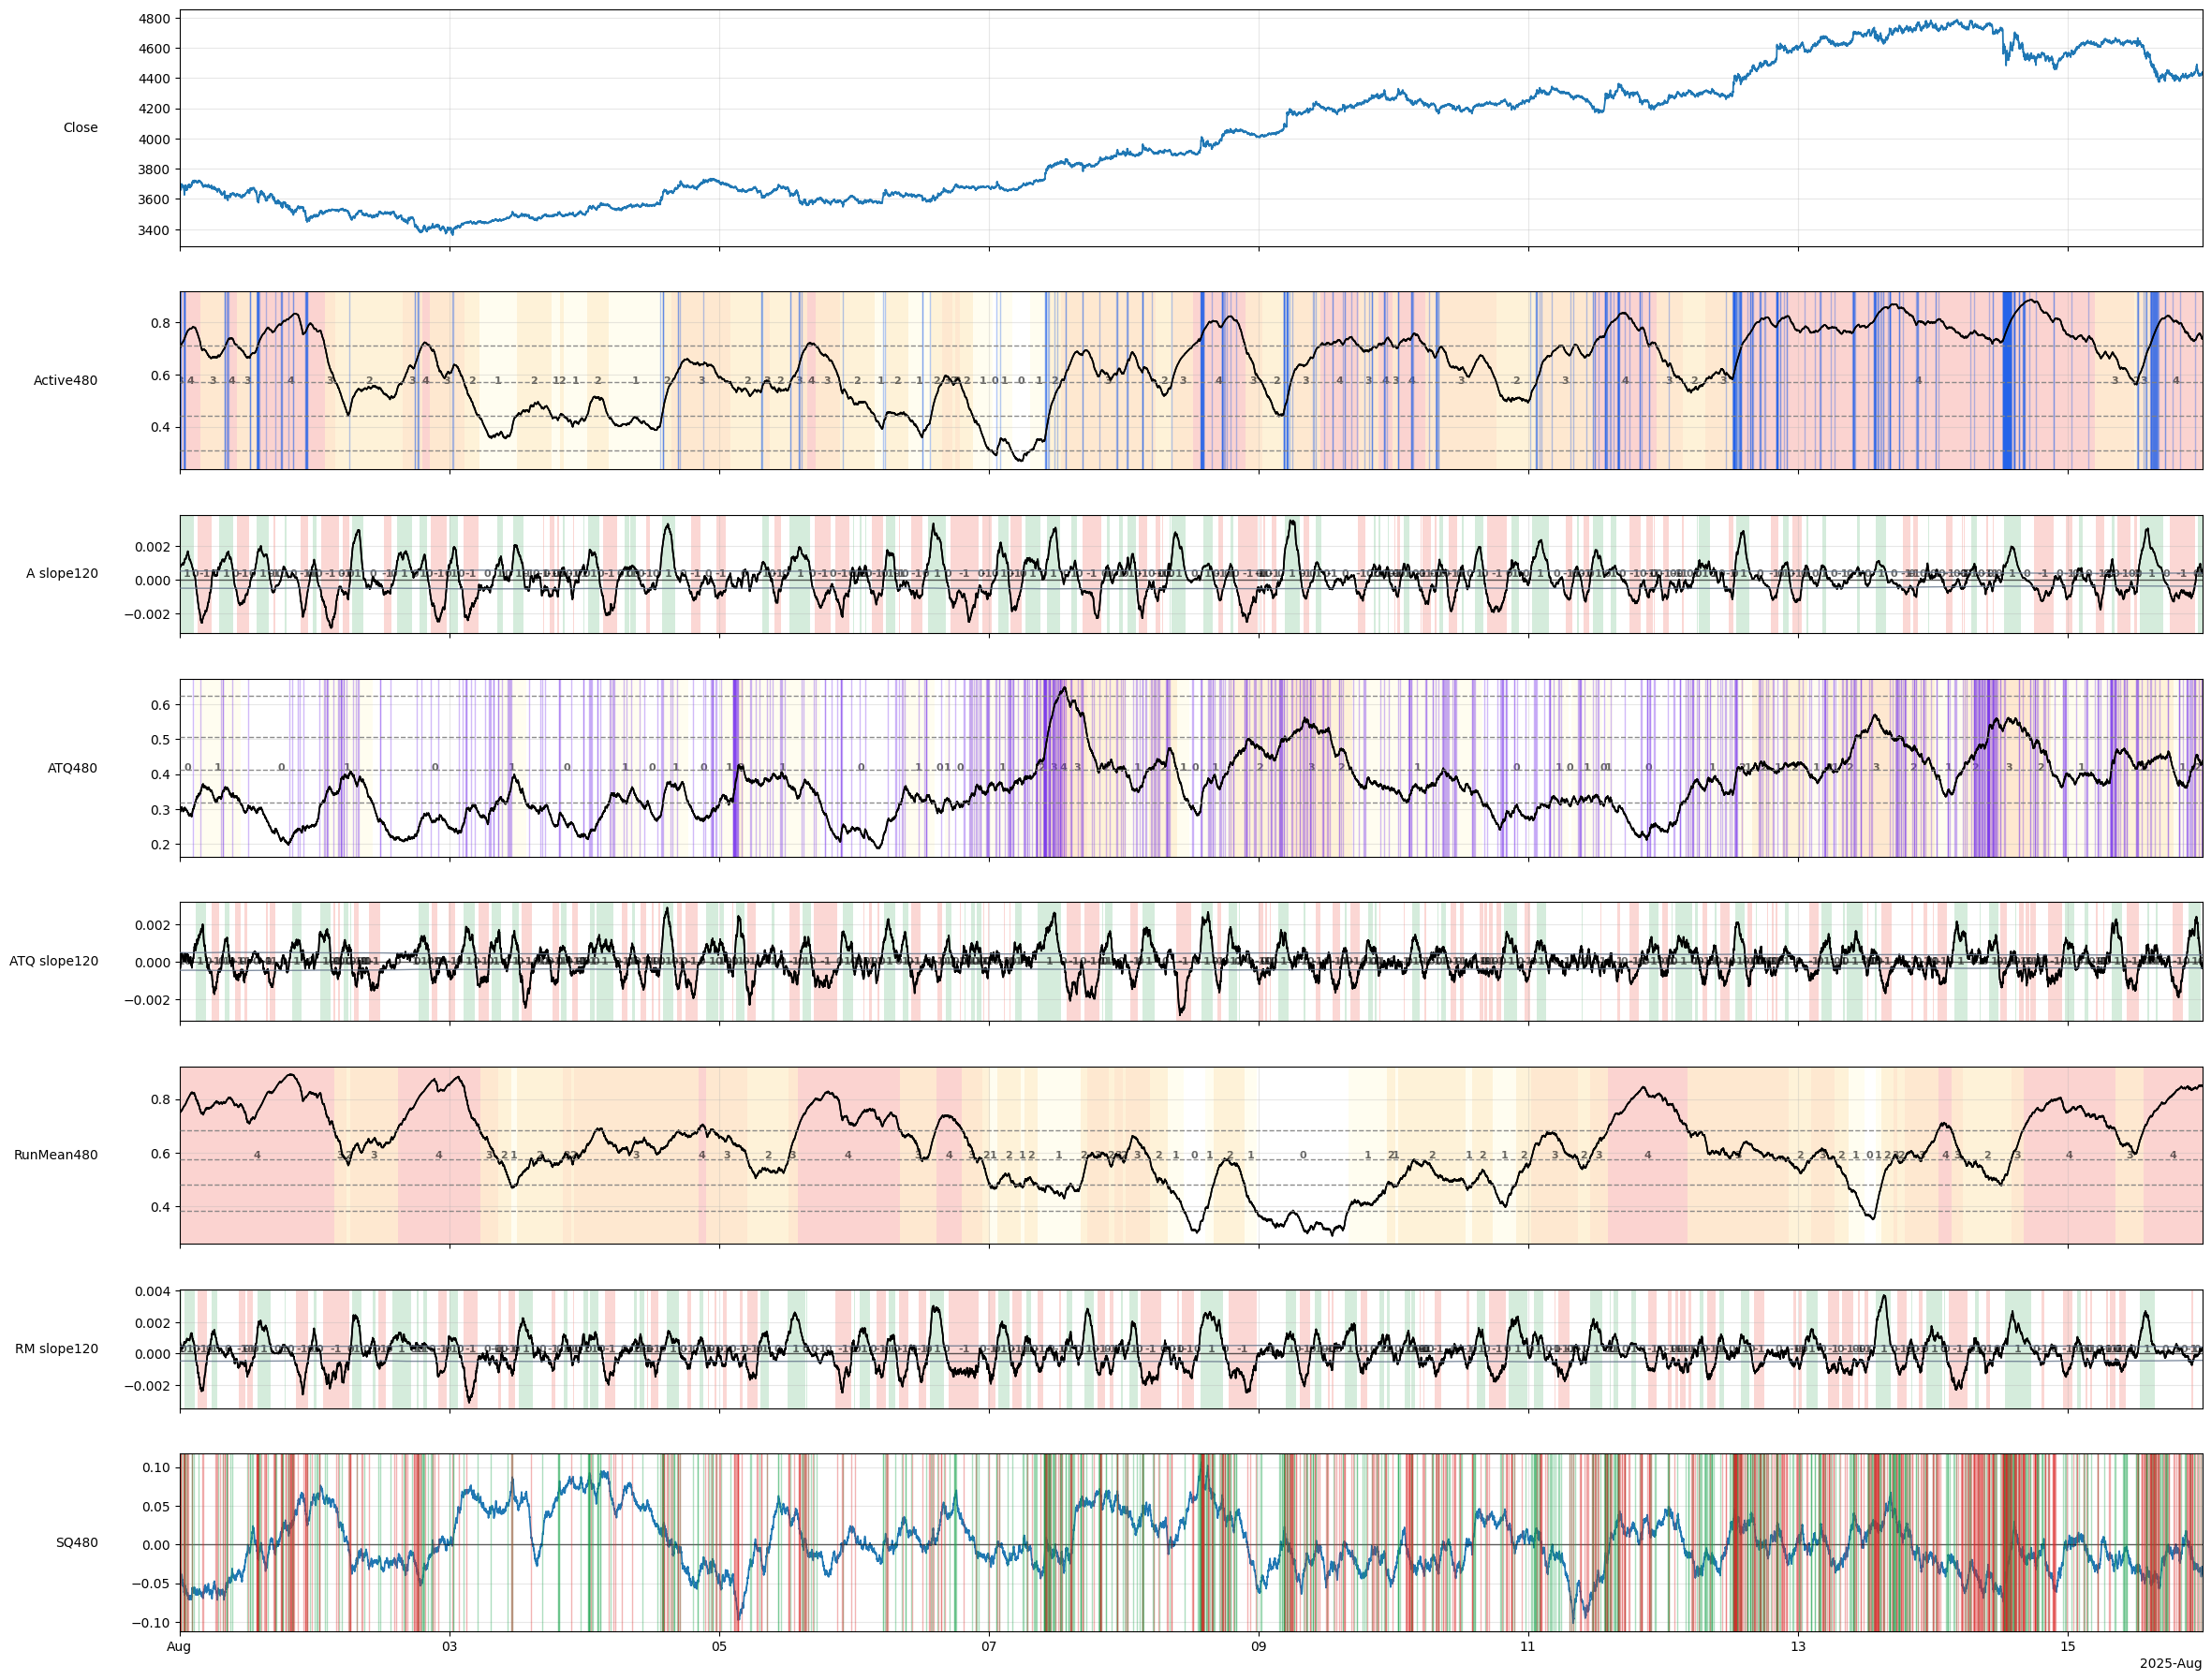

In [ ]:
plot_dashboard(pdf, panes, tcol="t", figsize=(24*1.5, 15*1.5), left_margin=0.30, t_start="2025-08-01", t_end="2025-08-16")

|  Group | ชื่อ Climate (เชิงระบบ)         | ลักษณะโครงสร้าง                    | Expectation   | บทบาทในระบบ         |
| -----: | ------------------------------- | ---------------------------------- | ------------- | ------------------- |
|  **2** | Dormant / Sleep                 | activity ต่ำ, size เล็ก, run ต่ำ   | ≈ 0 (stable)  | ❌ ไม่เล่น, baseline |
| **11** | Neutral / Background            | ทุกแกนกลาง ๆ                       | ≈ 0           | ❌ ไม่เล่น, buffer   |
|  **7** | Transition / Noisy              | แกนขัดกัน, ไม่ชัด                  | ≈ 0           | ⏸️ รอดู             |
|  **0** | Quiet Drift / Accumulation      | run สูง แต่ activity/size ต่ำ      | + เล็ก        | ✅ carry / passive   |
|  **8** | Range-Biased Accumulation       | activity คงที่, size ใหญ่, run ต่ำ | + เล็ก–กลาง   | ✅ mean-rev / carry  |
|  **9** | Micro Drift (Retail Bias)       | trade เล็ก, bias อ่อน              | + เล็ก        | ➕ เสริม (addon)     |
| **10** | Early Re-Engage                 | activity ต่ำ, run เริ่มสูง         | + ชัด (early) | 🔍 probe / build    |
|  **6** | Prime Expansion                 | ทุกแกนสมดุล, flow จริง             | +++           | 🟢 main engine      |
|  **1** | Broad Active Flow               | activity สูงมาก, flow หนา          | +             | 🟢 multi-strategy   |
|  **5** | Late Trend / Exhaustion         | run สูง แต่ efficiency แย่         | −             | ⚠️ ลดขนาด           |
|  **3** | Distribution / Decay            | size ใหญ่, run ไม่ต่อ              | −−            | 🔻 risk-off         |
|  **4** | Failed Expansion / Active Dist. | activity+run สูง แต่ drift ลบแรง   | −−−           | 🛑 stop / hedge     |


| Meta Climate       | Groups  | ความหมาย           |
| ------------------ | ------- | ------------------ |
| **Sleep**          | 2, 11   | ตลาดไม่ให้ edge    |
| **Quiet / Range**  | 0, 8, 9 | edge เล็ก, เล่นเบา |
| **Early**          | 10      | เตรียมก่อนของจริง  |
| **Prime**          | 6       | แหล่งทำเงินหลัก    |
|**Broad Active**    | 1       | คนเยอะ อาจมีโอกาส  |
| **Late / Warning** | 5       | ลดโลภ              |
| **Risk-Off**       | 3, 4    | ป้องกันพอร์ต       |


| Climate         | Momentum | Mean-Rev | Carry | Size        | Risk Mode  |
| --------------- | -------- | -------- | ----- | ----------- | ---------- |
| Sleep / Neutral | ❌        | ❌        | ❌     | 0           | Idle       |
| Quiet / Range   | ❌        | ✅        | ✅     | Small       | Low        |
| Early           | ⚠️       | ❌        | ⚠️    | Probe       | Controlled |
| **Prime**       | ✅        | ❌        | ⚠️    | Full        | Risk-On    |
| Broad Active    | ✅        | ⚠️       | ❌     | Medium      | Risk-On    |
| Late            | ❌        | ❌        | ❌     | Reduce      | Warning    |
| Risk-Off        | ❌        | ❌        | ❌     | Min / Hedge | Defensive  |


In [ ]:
# merged = data.drop([
#  'active_ms',
#  'flip_rate',
#  'avg_trade_q',
#  'run_mean',
#  'signed_quote',
#  'rv_sqrt',
#  'run_max',
#  'intensity_peak_1s',
# ]).join(
#     df.drop("close"),
#     on="t",
#     how="left"
# )
# merged.drop("climate_group").write_parquet("/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/df_q_fixed_L_to_Tree.parquet")

# Tree Base Model

In [ ]:
# Dependencies are installed once from requirements.txt.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 28.2 MB/s eta 0:00:00


In [ ]:
import polars as pl

df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_to_Tree.parquet")))

# Sprint 0 : Finding Edge

In [ ]:
import math
import numpy as np
import polars as pl

from catboost import CatBoostClassifier, Pool

from sklearn.metrics import (
    roc_auc_score, f1_score, confusion_matrix,
    precision_score
)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

In [ ]:
def sanity_check_time(df: pl.DataFrame, tcol="t") -> None:
    dt = df.schema[tcol]
    assert dt in (pl.Datetime, pl.Datetime("us"), pl.Datetime("ms"), pl.Datetime("ns")), f"{tcol} dtype is {dt}, not Datetime"
    # sorted?
    t = df[tcol].to_numpy()
    assert np.all(t[1:] >= t[:-1]), f"{tcol} is not monotonic non-decreasing"
sanity_check_time(df)

### Label Construction (Triple-Barrier, H=30)

1.1 Triple Barrier Labeler (y_tb30)

sigma_t = rv_sqrt_ema_480

U/L = close_t ± 1.0 * sigma_t * sqrt(30)

within next 30 bars: first hit (use high/low)

if is_missing_fill == True at t → label = NaN (drop later)

### +1,-,-1

In [ ]:
def add_tb30_label(
    df: pl.DataFrame,
    *,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    sigma_col="rv_sqrt_ema_480",
    missing_col="is_missing_fill",
    H=30,
    k=1.0,
    out_col="y_tb30",
) -> pl.DataFrame:
    df = df.sort(tcol)

    # mask rows with missing fill
    missing = df[missing_col].to_numpy().astype(bool)

    close = df[close_col].to_numpy().astype(float)
    high  = df[high_col].to_numpy().astype(float)
    low   = df[low_col].to_numpy().astype(float)
    sigma = df[sigma_col].to_numpy().astype(float)

    n = len(df)
    y = np.full(n, np.nan, dtype=float)

    # barriers at t
    scale = k * np.sqrt(H)
    U = close + sigma * scale
    L = close - sigma * scale

    # label each t by scanning future bars [t+1 ... t+H]
    # (you can include t itself if you want; here we use strictly future)
    for i in range(n):
        if missing[i]:
            y[i] = np.nan
            continue
        if i + H >= n:
            y[i] = np.nan
            continue

        ui = U[i]
        li = L[i]

        hit = 0
        for j in range(i + 1, i + H + 1):
            # if both hit in same bar, choose "closest to open" is ambiguous w/o intrabar path.
            # We'll break ties by checking which side is crossed "more extremely" first is unknowable.
            # Practical tie rule: if both hit same bar -> 0 (neutral). (conservative)
            up = high[j] >= ui
            dn = low[j] <= li

            if up and dn:
                hit = 0
                break
            if up:
                hit = +1
                break
            if dn:
                hit = -1
                break

        y[i] = hit

    return df.with_columns(pl.Series(out_col, y))

In [ ]:
def add_tb30_label_with_report(
    df: pl.DataFrame,
    *,
    tcol="t",
    close_col="close",
    high_col="high",
    low_col="low",
    sigma_col="rv_sqrt_ema_480",
    missing_col="is_missing_fill",
    H=30,
    k=1.0,
    out_col="y_tb30",
):
    df = df.sort(tcol)
    sanity_check_time(df, tcol=tcol)

    missing = df[missing_col].to_numpy().astype(bool)
    close = df[close_col].to_numpy().astype(float)
    high  = df[high_col].to_numpy().astype(float)
    low   = df[low_col].to_numpy().astype(float)
    sigma = df[sigma_col].to_numpy().astype(float)

    n = len(df)
    y = np.full(n, np.nan, dtype=float)
    tie = np.zeros(n, dtype=bool)

    scale = k * np.sqrt(H)
    U = close + sigma * scale
    L = close - sigma * scale

    width_bps = (U - L) / close * 1e4  # per-row

    for i in range(n):
        if missing[i] or (i + H >= n):
            y[i] = np.nan
            continue

        ui, li = U[i], L[i]
        hit = 0
        tied = False

        for j in range(i + 1, i + H + 1):
            up = high[j] >= ui
            dn = low[j] <= li
            if up and dn:
                hit = 0
                tied = True
                break
            if up:
                hit = +1
                break
            if dn:
                hit = -1
                break

        y[i] = hit
        tie[i] = tied

    out = df.with_columns([
        pl.Series(out_col, y),
        pl.Series(out_col + "_tie", tie),
        pl.Series(out_col + "_width_bps", width_bps),
    ])

    # report (on valid labeled rows only)
    rep = (
        out.filter(pl.col(out_col).is_not_null() & pl.col(out_col).is_finite())
           .select([
               pl.col(out_col + "_tie").mean().alias("tie_rate"),
               pl.col(out_col + "_width_bps").median().alias("width_bps_median"),
               pl.col(out_col + "_width_bps").quantile(0.90).alias("width_bps_p90"),
           ])
    )
    return out, rep

In [ ]:
df1, label_rep = add_tb30_label_with_report(df, H=30, out_col="y_tb30")
print(label_rep)

# drop missing-fill rows + invalid labels
df1 = df1.filter((~pl.col("is_missing_fill")) & pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())

shape: (1, 3)
┌──────────┬──────────────────┬───────────────┐
│ tie_rate ┆ width_bps_median ┆ width_bps_p90 │
│ ---      ┆ ---              ┆ ---           │
│ f64      ┆ f64              ┆ f64           │
╞══════════╪══════════════════╪═══════════════╡
│ 0.76191  ┆ 0.018195         ┆ 0.290873      │
└──────────┴──────────────────┴───────────────┘


In [ ]:
df1 = add_tb30_label(df, H=30, out_col="y_tb30")

In [ ]:
# Drop rows with missing fill or label NaN
df1 = df1.filter(
    (~pl.col("is_missing_fill")) &
    (pl.col("y_tb30").is_not_null())
)

In [ ]:
summary = (
    df1.select(pl.col("y_tb30"))
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .group_by("y_tb30")
       .len()
       .with_columns((pl.col("len") / pl.col("len").sum()).alias("pct"))
       .sort("y_tb30")
)

In [ ]:
summary

y_tb30,len,pct
i8,u32,f64
-1,375219,0.118962
0,2403304,0.761962
1,375577,0.119076


### Feature Gating (≤ 50 columns)

In [ ]:
df.columns

['t',
 'open',
 'high',
 'low',
 'close',
 'vol_base',
 'vol_quote',
 'trade_count',
 'buy_count',
 'sell_count',
 'buy_quote',
 'sell_quote',
 'vwap',
 'trade_rate',
 'imbalance',
 'range',
 'hl_pct',
 'prev_close',
 'ret_inbar',
 'ret_cc',
 'gap_oc',
 'dt_mean_ms',
 'dt_median_ms',
 'dt_p90_ms',
 'frac_dt0',
 'realized_var_inbar',
 'dp0_frac',
 'n_price_changes',
 'up_ticks',
 'down_ticks',
 'max_up_move',
 'max_down_move',
 'n_returns',
 'avg_trade_notional',
 'q_p50',
 'q_p90',
 'q_p99',
 'notional_p90',
 'notional_p99',
 'top1_share',
 'sign_persistence_inbar',
 'flip_count',
 'sign_entropy',
 'n_trans',
 'is_sparse_stats',
 'is_sparse_seq',
 'is_sparse_top1',
 'gap_ms_from_last_trade',
 'is_no_trade_fill',
 'is_missing_fill',
 'active_ms',
 'flip_rate',
 'avg_trade_q',
 'run_mean',
 'signed_quote',
 'rv_sqrt',
 'run_max',
 'intensity_peak_1s',
 'active_ms_rank_like_Lint',
 'active_ms_rank_ema_30',
 'active_ms_rank_ema_120',
 'active_ms_rank_ema_480',
 'active_ms_rank_ema_1440',
 

In [ ]:
def gate_features_phase0_strict(df: pl.DataFrame) -> list[str]:
    cols = df.columns
    allow = []

    # dynamics (pattern match by "in" OK เพราะ specific มาก)
    dyn_patterns = [
        "_rank_ema_120_slope_30",
        "_rank_ema_120_slope_120",
        "_accel_120",
    ]
    for c in cols:
        if any(p in c for p in dyn_patterns):
            allow.append(c)

    # signed quote pressure (explicit)
    sq_allow = [
        "sq_rank_with_sign",
        "sq_rank_with_sign_rank_ema_30",
        "sq_rank_with_sign_rank_ema_120",
    ]
    for c in sq_allow:
        if c in cols:
            allow.append(c)

    # events strict suffix ONLY
    for c in cols:
        if c.endswith("_evt_frac_60m") or c.endswith("_evt") or c.endswith("_sev"):
            # hard ban climate/bin family
            if ("climate" in c) or ("_bin" in c) or ("robust" in c) or ("_grp" in c) or ("_streak" in c) or ("_pending" in c):
                continue
            allow.append(c)

    # context
    ctx = ["rv_sqrt_ema_480", "rv_sqrt_ema_1440", "active_ms_rank_ema_120"]
    for c in ctx:
        if c in cols:
            allow.append(c)

    # dedup keep order
    seen = set()
    allow2 = []
    for c in allow:
        if c not in seen:
            allow2.append(c); seen.add(c)

    # cap 50 with deterministic priority
    def priority(c: str) -> int:
        if c in sq_allow: return 0
        if c in ctx: return 1
        if "_accel_120" in c: return 2
        if "_rank_ema_120_slope_" in c: return 3
        if c.endswith("_evt_frac_60m"): return 4
        if c.endswith("_sev"): return 5
        if c.endswith("_evt"): return 6
        return 9

    allow2 = sorted(allow2, key=lambda x: (priority(x), x))[:50]
    return allow2

In [ ]:
FEATURES = gate_features_phase0_strict(df1)

In [ ]:
print("Feature count:", len(FEATURES))
FEATURES

Feature count: 50


['sq_rank_with_sign',
 'sq_rank_with_sign_rank_ema_120',
 'sq_rank_with_sign_rank_ema_30',
 'active_ms_rank_ema_120',
 'rv_sqrt_ema_1440',
 'rv_sqrt_ema_480',
 'sq_rank_with_sign_rank_ema_480_accel_120',
 'active_ms_rank_ema_120_slope_120',
 'active_ms_rank_ema_120_slope_120_bin3_robust',
 'active_ms_rank_ema_120_slope_120_bin3_robust_grp',
 'active_ms_rank_ema_120_slope_120_bin3_robust_pending',
 'active_ms_rank_ema_120_slope_120_bin3_robust_raw',
 'active_ms_rank_ema_120_slope_120_bin3_robust_streak',
 'active_ms_rank_ema_120_slope_120_mad',
 'active_ms_rank_ema_120_slope_120_med',
 'active_ms_rank_ema_120_slope_120_tau',
 'active_ms_rank_ema_120_slope_30',
 'avg_trade_q_rank_ema_120_slope_120',
 'avg_trade_q_rank_ema_120_slope_120_bin3_robust',
 'avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp',
 'avg_trade_q_rank_ema_120_slope_120_bin3_robust_pending',
 'avg_trade_q_rank_ema_120_slope_120_bin3_robust_raw',
 'avg_trade_q_rank_ema_120_slope_120_bin3_robust_streak',
 'avg_trade_q_r

In [ ]:
model_df = (
    df1.select(["t", "y_tb30"] + FEATURES)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

sanity_check_time(model_df, "t")
print("n(model_df) =", model_df.height, "n_features =", len(FEATURES))

n(model_df) = 3154100 n_features = 50


### Walk-Forward Split + Purge/Embargo

In [ ]:
def walk_forward_split_purged_on_df(
    df: pl.DataFrame,
    *,
    tcol="t",
    purge_min=30,
    embargo_min=60,
    train_frac=0.60,
    val_frac=0.20,
):
    df = df.sort(tcol)
    t = df[tcol].to_numpy()
    n = len(t)

    i1 = int(n * train_frac)
    i2 = int(n * (train_frac + val_frac))
    t1, t2 = t[i1], t[i2]

    purge = np.timedelta64(purge_min, "m")
    embargo = np.timedelta64(embargo_min, "m")

    train_m = (t <= (t1 - purge))
    val_m   = (t >= (t1 + embargo)) & (t <= (t2 - purge))
    test_m  = (t >= (t2 + embargo))

    # sanity: strict disjoint + cover check
    assert not np.any(train_m & val_m)
    assert not np.any(train_m & test_m)
    assert not np.any(val_m & test_m)
    assert train_m.sum() > 0 and val_m.sum() > 0 and test_m.sum() > 0

    return train_m, val_m, test_m, (t1, t2)

train_m, val_m, test_m, (t1, t2) = walk_forward_split_purged_on_df(model_df)

In [ ]:
# deliverable index list
train_idx = np.where(train_m)[0].tolist()
val_idx   = np.where(val_m)[0].tolist()
test_idx  = np.where(test_m)[0].tolist()

print(len(train_idx), len(val_idx), len(test_idx))

1892431 630731 630760


### Model Training (CatBoost MultiClass) + Metrics + Calibration

In [ ]:
def to_numpy_Xy(df: pl.DataFrame, feature_cols: list[str], ycol: str):
    pdf = df.select(feature_cols + [ycol]).to_pandas()
    X = pdf[feature_cols].to_numpy(dtype=float)
    y = pdf[ycol].to_numpy()
    return X, y

#### Binary: hit vs no-hit (y!=0)

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def make_binary(df: pl.DataFrame):
    return df.with_columns((pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"))

df_bin = make_binary(model_df)

train_df = df_bin.filter(pl.Series("m", train_m))
val_df   = df_bin.filter(pl.Series("m", val_m))
test_df  = df_bin.filter(pl.Series("m", test_m))

Xtr, ytr = to_numpy_Xy(train_df, FEATURES, "y_hit")
Xva, yva = to_numpy_Xy(val_df, FEATURES, "y_hit")
Xte, yte = to_numpy_Xy(test_df, FEATURES, "y_hit")

In [ ]:
cb_hit = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.07,
    iterations=2000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

cb_hit.fit(Xtr, ytr, eval_set=(Xva, yva), use_best_model=True, early_stopping_rounds=200)

0:	test: 0.6286899	best: 0.6286899 (0)	total: 365ms	remaining: 12m 9s
200:	test: 0.6630238	best: 0.6630238 (200)	total: 42.8s	remaining: 6m 23s
400:	test: 0.6642920	best: 0.6642920 (400)	total: 1m 28s	remaining: 5m 51s
600:	test: 0.6644110	best: 0.6644669 (461)	total: 2m 8s	remaining: 4m 59s
800:	test: 0.6641748	best: 0.6644679 (622)	total: 2m 49s	remaining: 4m 13s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6644679069
bestIteration = 622

Shrink model to first 623 iterations.


In [ ]:
p_hit = cb_hit.predict_proba(Xte)[:, 1]
pr_auc = average_precision_score(yte, p_hit)
roc_auc = roc_auc_score(yte, p_hit)
print({"binary_pr_auc": pr_auc, "binary_roc_auc": roc_auc})

{'binary_pr_auc': np.float64(0.3485627826819311), 'binary_roc_auc': np.float64(0.6211566362307485)}


#### Directional: เฉพาะ y!=0 แล้ว train +1 vs -1

In [ ]:
df_dir = model_df.filter(pl.col("y_tb30") != 0).with_columns(
    (pl.col("y_tb30") == 1).cast(pl.Int8).alias("y_up")   # 1 => +1, 0 => -1
)

train_df2 = df_dir.filter(pl.Series("m", train_m[:df_dir.height] if df_dir.height != model_df.height else train_m))
val_df2   = df_dir.filter(pl.Series("m", val_m[:df_dir.height] if df_dir.height != model_df.height else val_m))
test_df2  = df_dir.filter(pl.Series("m", test_m[:df_dir.height] if df_dir.height != model_df.height else test_m))

# IMPORTANT: mask ต้อง alignกับ df_dir จริง ๆ => สร้าง split ใหม่บน df_dir เพื่อชัวร์
train_m2, val_m2, test_m2, _ = walk_forward_split_purged_on_df(df_dir)
train_df2 = df_dir.filter(pl.Series("m", train_m2))
val_df2   = df_dir.filter(pl.Series("m", val_m2))
test_df2  = df_dir.filter(pl.Series("m", test_m2))

Xtr2, ytr2 = to_numpy_Xy(train_df2, FEATURES, "y_up")
Xva2, yva2 = to_numpy_Xy(val_df2, FEATURES, "y_up")
Xte2, yte2 = to_numpy_Xy(test_df2, FEATURES, "y_up")

In [ ]:
cb_dir = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.07,
    iterations=2000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

cb_dir.fit(Xtr2, ytr2, eval_set=(Xva2, yva2), use_best_model=True, early_stopping_rounds=200)

0:	test: 0.5149186	best: 0.5149186 (0)	total: 57.8ms	remaining: 1m 55s
200:	test: 0.5129669	best: 0.5175794 (6)	total: 11.5s	remaining: 1m 42s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.5175793796
bestIteration = 6

Shrink model to first 7 iterations.


In [ ]:
proba = cb_dir.predict_proba(Xte2)
p_up = proba[:, 1]
p_dn = 1.0 - p_up
score = p_up - p_dn  # == 2*p_up - 1

# Precision@Top10% using score (positive means +1)
k = max(1, int(0.10 * len(score)))
top_idx = np.argsort(-score)[:k]
prec_top10 = (yte2[top_idx] == 1).mean()
print({"directional_precision_at_top10_score": float(prec_top10)})

{'directional_precision_at_top10_score': 0.526007326007326}


### SHAP top10

In [ ]:
def shap_top10_mean_abs(model: CatBoostClassifier, X: np.ndarray, feature_names: list[str], class_index: int | None = None, N=5000):
    N = min(N, X.shape[0])
    pool = Pool(X[:N], feature_names=feature_names)
    sv = np.array(model.get_feature_importance(pool, type="ShapValues"))

    # Binary Logloss: (N, F+1)
    if sv.ndim == 2:
        vals = sv[:, :-1]
    # Multiclass: (N, F+1, C)
    elif sv.ndim == 3:
        assert class_index is not None
        vals = sv[:, :-1, class_index]
    else:
        raise ValueError(f"Unexpected SHAP shape: {sv.shape}")

    mean_abs = np.mean(np.abs(vals), axis=0)
    idx = np.argsort(-mean_abs)[:10]
    return [(feature_names[i], float(mean_abs[i])) for i in idx]

print("SHAP top10 (binary hit):", shap_top10_mean_abs(cb_hit, Xte, FEATURES))
print("SHAP top10 (directional up):", shap_top10_mean_abs(cb_dir, Xte2, FEATURES))

SHAP top10 (binary hit): [('rv_sqrt_ema_480', 0.45463423038623807), ('active_ms_rank_ema_120_slope_120_bin3_robust_grp', 0.14601510598477627), ('active_ms_rank_ema_120', 0.11257614765332173), ('active_ms_rank_ema_120_slope_30', 0.08473027853121957), ('sq_rank_with_sign', 0.06710738354270963), ('avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp', 0.06537697718250556), ('run_mean_q_rank_ema_120_slope_120_bin3_robust_grp', 0.04789644202997846), ('active_ms_evt_frac_60m', 0.03700883752750613), ('sq_rank_with_sign_rank_ema_30', 0.02887893143213205), ('rv_sqrt_ema_1440', 0.027934453720192032)]
SHAP top10 (directional up): [('sq_rank_with_sign', 0.006675628827235799), ('sq_rank_with_sign_rank_ema_30', 0.004286756080503463), ('run_mean_q_rank_ema_120_slope_120_bin3_robust_grp', 0.00420041184668064), ('avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp', 0.003949785068833441), ('rv_sqrt_ema_480', 0.003717888636892842), ('sq_rank_with_sign_rank_ema_480_accel_120', 0.0013971156441008616), ('rv_s

### Climate Context

In [ ]:
CLIMATE_COLS = [
    "climate_state",
    "active_ms_rank_ema_480_bin_c",
    "avg_trade_q_rank_ema_480_bin_c",
    "run_mean_q_rank_ema_480_bin_c",
]

for c in CLIMATE_COLS:
    assert c in df1.columns, f"missing climate feature: {c}"

In [ ]:
model_df_c = (
    df1.select(["t", "y_tb30"] + FEATURES + CLIMATE_COLS)
       .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
       .with_columns(pl.col("y_tb30").cast(pl.Int8))
       .sort("t")
)

sanity_check_time(model_df_c, "t")

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

def metrics_by_climate_binary(df_test, p_hit):
    pdf = df_test.select(["climate_state", "y_hit"]).to_pandas()
    pdf["p"] = p_hit

    rows = []
    for c, g in pdf.groupby("climate_state"):
        if g["y_hit"].nunique() < 2:
            continue
        rows.append({
            "climate_state": c,
            "n": len(g),
            "roc_auc": roc_auc_score(g["y_hit"], g["p"]),
            "pr_auc": average_precision_score(g["y_hit"], g["p"]),
        })
    return pl.DataFrame(rows)

In [ ]:
def precision_top10_directional(df_test, score):
    pdf = df_test.select(["climate_state", "y_up"]).to_pandas()
    pdf["score"] = score

    rows = []
    for c, g in pdf.groupby("climate_state"):
        if len(g) < 100:
            continue
        k = max(1, int(0.10 * len(g)))
        top = g.sort_values("score", ascending=False).head(k)
        rows.append({
            "climate_state": c,
            "n": len(g),
            "precision_top10": (top["y_up"] == 1).mean(),
        })
    return pl.DataFrame(rows)

In [ ]:
bin_table = metrics_by_climate_binary(
    df_test=test_df,
    p_hit=p_te
)

dir_table = precision_top10_directional(
    df_test=test_df2,
    score=score
)

climate_metrics = (
    bin_table.join(dir_table, on="climate_state", how="outer")
              .sort("climate_state")
)

/tmp/ipython-input-2542118664.py:12: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  bin_table.join(dir_table, on="climate_state", how="outer")


In [ ]:
climate_metrics

climate_state,n,roc_auc,pr_auc,climate_state_right,n_right,precision_top10
str,i64,f64,f64,str,i64,f64
"""0_0_0""",1585,0.542652,0.469566,"""0_0_0""",667,0.545455
"""0_0_1""",1969,0.536276,0.431171,"""0_0_1""",673,0.597015
"""0_0_2""",1376,0.52687,0.394217,"""0_0_2""",459,0.6
"""0_0_3""",384,0.495833,0.278086,"""0_0_3""",107,0.5
"""0_1_0""",11464,0.572939,0.475495,"""0_1_0""",4751,0.56
…,…,…,…,…,…,…
"""4_4_0""",6418,0.578308,0.169595,"""4_4_0""",868,0.534884
"""4_4_1""",6244,0.573504,0.192414,"""4_4_1""",968,0.447917
"""4_4_2""",8684,0.572554,0.162522,"""4_4_2""",1165,0.594828


Before feeding climate into the model, the detected edge is already highly regime-dependent: strong and stable in a subset of climate states, and indistinguishable from noise in others.

# Sprint 1 — Discrete Context Control

Assumptions (ยึดจาก Sprint 0)

model_df มี:
- t, y_tb30
- features จาก Sprint 0
- binary model = hit vs no-hit
- directional model = +1 vs -1 (เฉพาะ hit)
- split / purge / embargo เหมือนเดิม

เพิ่ม Climate Features

### Add Climate FEATURES

In [ ]:
FEATURES = FEATURES + [
    "climate_state",
    "active_ms_rank_ema_480_bin_c",
    "avg_trade_q_rank_ema_480_bin_c",
    "run_mean_q_rank_ema_480_bin_c",
]

In [ ]:
def to_pandas_Xy(df: pl.DataFrame, feature_cols: list[str], ycol="y_hit"):
    pdf = df.select(feature_cols + [ycol]).to_pandas()
    X = pdf[feature_cols]          # pandas DataFrame
    y = pdf[ycol].to_numpy()
    return X, y

#### hit

In [ ]:
df_bin = model_df_c.with_columns(
    (pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit")
).with_columns([
    pl.col("climate_state").cast(pl.Utf8).fill_null("__MISSING__"),

    # bin_c อาจเป็น int/float -> cast to Int/Utf8 แล้ว fill null
    pl.col("active_ms_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
    pl.col("avg_trade_q_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
    pl.col("run_mean_q_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
])

train_m, val_m, test_m, _ = walk_forward_split_purged_on_df(df_bin)

train_df = df_bin.filter(pl.Series("m", train_m))
val_df   = df_bin.filter(pl.Series("m", val_m))
test_df  = df_bin.filter(pl.Series("m", test_m))

In [ ]:
from catboost import Pool

cat_cols = [
    "climate_state",
    "active_ms_rank_ema_480_bin_c",
    "avg_trade_q_rank_ema_480_bin_c",
    "run_mean_q_rank_ema_480_bin_c",
]

Xtr, ytr = to_pandas_Xy(train_df, FEATURES, "y_hit")
Xva, yva = to_pandas_Xy(val_df, FEATURES, "y_hit")
Xte, yte = to_pandas_Xy(test_df, FEATURES, "y_hit")

train_pool = Pool(Xtr, ytr, cat_features=cat_cols)
val_pool   = Pool(Xva, yva, cat_features=cat_cols)
test_pool = Pool(Xte, yte, cat_features=cat_cols)

In [ ]:
cb_hit2 = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.07,
    iterations=2000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

In [ ]:
cb_hit2.fit(
    train_pool,
    eval_set=val_pool,
    use_best_model=True,
    early_stopping_rounds=200,
)

0:	test: 0.6378386	best: 0.6378386 (0)	total: 1.17s	remaining: 39m 1s
200:	test: 0.6648373	best: 0.6648373 (200)	total: 2m 32s	remaining: 22m 43s
400:	test: 0.6656171	best: 0.6656171 (400)	total: 5m 6s	remaining: 20m 22s
600:	test: 0.6658650	best: 0.6658730 (591)	total: 7m 46s	remaining: 18m 6s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.6658730006
bestIteration = 591

Shrink model to first 592 iterations.


In [ ]:
p_hit2 = cb_hit2.predict_proba(test_pool)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
roc2 = roc_auc_score(yte, p_hit2)
pr2  = average_precision_score(yte, p_hit2)
print({"binary_roc_auc": roc2, "binary_pr_auc": pr2})

{'binary_roc_auc': np.float64(0.6212200035000568), 'binary_pr_auc': np.float64(0.34830728439822123)}


#### dir

In [ ]:
df_dir = model_df_c.filter(pl.col("y_tb30") != 0).with_columns(
    (pl.col("y_tb30") == 1).cast(pl.Int8).alias("y_up")
).with_columns([
    pl.col("climate_state").cast(pl.Utf8).fill_null("__MISSING__"),
    pl.col("active_ms_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
    pl.col("avg_trade_q_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
    pl.col("run_mean_q_rank_ema_480_bin_c").cast(pl.Int16).fill_null(-1),
])

train_m2, val_m2, test_m2, _ = walk_forward_split_purged_on_df(df_dir)

train_df2 = df_dir.filter(pl.Series("m", train_m2))
val_df2   = df_dir.filter(pl.Series("m", val_m2))
test_df2  = df_dir.filter(pl.Series("m", test_m2))

In [ ]:
Xtr2, ytr2 = to_pandas_Xy(train_df2, FEATURES, "y_up")
Xva2, yva2 = to_pandas_Xy(val_df2, FEATURES, "y_up")
Xte2, yte2 = to_pandas_Xy(test_df2, FEATURES, "y_up")

train_pool2 = Pool(Xtr2, ytr2, cat_features=cat_cols)
val_pool2   = Pool(Xva2, yva2, cat_features=cat_cols)
test_pool2  = Pool(Xte2, yte2, cat_features=cat_cols)

In [ ]:
cb_dir2 = CatBoostClassifier(
    loss_function="Logloss",
    depth=7,
    learning_rate=0.07,
    iterations=2000,
    auto_class_weights="Balanced",
    eval_metric="AUC",
    random_seed=42,
    verbose=200,
)

In [ ]:
cb_dir2.fit(
    train_pool2,
    eval_set=val_pool2,
    use_best_model=True,
    early_stopping_rounds=200,
)

0:	test: 0.5133952	best: 0.5133952 (0)	total: 188ms	remaining: 6m 15s
200:	test: 0.5137563	best: 0.5181283 (2)	total: 38.7s	remaining: 5m 46s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.5181283432
bestIteration = 2

Shrink model to first 3 iterations.


In [ ]:
proba2 = cb_dir2.predict_proba(test_pool2)
score2 = proba2[:, 1] - proba2[:, 0]   # P(+1)-P(-1)

k = max(1, int(0.10 * len(score2)))
top_idx = np.argsort(-score2)[:k]
prec_top10_2 = (yte2[top_idx] == 1).mean()
print({"directional_precision_at_top10_score": float(prec_top10_2)})

{'directional_precision_at_top10_score': 0.5207459207459207}


### SHAP top10

In [ ]:
def shap_top10_mean_abs_cb(
    model: CatBoostClassifier,
    X,                       # pandas DataFrame (แนะนำ)
    feature_names: list[str],
    cat_cols: list[str] | None = None,
    class_index: int | None = None,
    N: int = 5000,
):
    N = min(N, len(X))
    XN = X.iloc[:N].copy()

    # สำคัญ: ใส่ cat_features ให้ตรงกับตอนเทรน
    pool = Pool(
        XN,
        feature_names=feature_names,
        cat_features=cat_cols
    )

    sv = np.array(model.get_feature_importance(pool, type="ShapValues"))

    # Binary Logloss: (N, F+1)
    if sv.ndim == 2:
        vals = sv[:, :-1]
    # Multiclass: (N, F+1, C)
    elif sv.ndim == 3:
        assert class_index is not None
        vals = sv[:, :-1, class_index]
    else:
        raise ValueError(f"Unexpected SHAP shape: {sv.shape}")

    mean_abs = np.mean(np.abs(vals), axis=0)
    idx = np.argsort(-mean_abs)[:10]
    return [(feature_names[i], float(mean_abs[i])) for i in idx]

In [ ]:
print(
    "SHAP top10 (binary hit):",
    shap_top10_mean_abs_cb(
        cb_hit2,
        Xte,
        FEATURES,
        cat_cols=cat_cols,   # << ใส่ตัวนี้
        N=5000
    )
)

SHAP top10 (binary hit): [('rv_sqrt_ema_480', 0.5172155901372213), ('active_ms_rank_ema_120_slope_120_bin3_robust_grp', 0.15741338767457172), ('active_ms_rank_ema_120', 0.09578256813268794), ('avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp', 0.08901632424930218), ('active_ms_rank_ema_120_slope_30', 0.08868788807227325), ('sq_rank_with_sign', 0.0682973268253023), ('run_mean_q_rank_ema_120_slope_120_bin3_robust_grp', 0.06241925031170127), ('active_ms_evt_frac_60m', 0.035492753768596584), ('rv_sqrt_ema_1440', 0.027828429623270996), ('active_ms_rank_ema_120_slope_120_tau', 0.02649138299554757)]


In [ ]:
print(
    "SHAP top10 (direction):",
    shap_top10_mean_abs_cb(
        cb_dir2,
        Xte2,
        FEATURES,
        cat_cols=cat_cols,
        N=5000
    )
)

SHAP top10 (direction): [('sq_rank_with_sign', 0.002929792203294939), ('active_ms_rank_ema_120_slope_120_bin3_robust_grp', 0.0027164023472319096), ('sq_rank_with_sign_rank_ema_30', 0.0023410488737428325), ('rv_sqrt_ema_480', 0.002299353403920803), ('run_mean_q_rank_ema_120_slope_30', 0.0011946042734787086), ('rv_sqrt_ema_1440', 0.0010079328370322905), ('run_mean_q_rank_ema_120_slope_120_bin3_robust_grp', 0.0004535230274233424), ('run_mean_q_rank_ema_120_slope_120_med', 0.00040204672160808777), ('run_max_evt_frac_60m', 0.0003728201629351756), ('avg_trade_q_rank_ema_120_slope_120_bin3_robust_grp', 0.0003719793848953592)]


### Climate Context

In [ ]:
bin_table2 = metrics_by_climate_binary(
    df_test=test_df,
    p_hit=p_hit2
)

dir_table2 = precision_top10_directional(
    df_test=test_df2,
    score=score2
)

climate_metrics2 = (
    bin_table2.join(dir_table2, on="climate_state", how="outer")
              .sort("climate_state")
)

/tmp/ipython-input-3408634603.py:12: DeprecationWarning: use of `how='outer'` should be replaced with `how='full'`.
(Deprecated in version 0.20.29)
  bin_table2.join(dir_table2, on="climate_state", how="outer")


In [ ]:
climate_metrics2

climate_state,n,roc_auc,pr_auc,climate_state_right,n_right,precision_top10
str,i64,f64,f64,str,i64,f64
"""0_0_0""",1585,0.542426,0.462482,"""0_0_0""",667,0.439394
"""0_0_1""",1969,0.535232,0.431883,"""0_0_1""",673,0.522388
"""0_0_2""",1376,0.528584,0.398317,"""0_0_2""",459,0.622222
"""0_0_3""",384,0.507709,0.287036,"""0_0_3""",107,0.7
"""0_1_0""",11464,0.576066,0.478923,"""0_1_0""",4751,0.52
…,…,…,…,…,…,…
"""4_4_0""",6418,0.572084,0.169958,"""4_4_0""",868,0.523256
"""4_4_1""",6244,0.577832,0.195655,"""4_4_1""",968,0.489583
"""4_4_2""",8684,0.570281,0.167974,"""4_4_2""",1165,0.491379


In [ ]:
climate_metrics.write_csv("climate_metrics_after_climate_to_model.csv")

## Sprint 1B : สมมติฐาน 125 Discrete climate

สมมติฐาน : climate ไม่ใช่ signal แต่คือ context ที่บอกว่า signal ใช้ได้ตอนไหน

เราจะสร้าง กฎคัดเลือก climate
ที่ “ไม่หลงกับเลขสวยจากข้อมูลช่วงเดียว”

แบ่งข้อมูลเป็นหลายช่วงเวลา (เช่น 5 ช่วง)

แต่ละช่วง:
- เทรนโมเดลเหมือนเดิม (ไม่ใส่ climate)
- เอา prediction ไปวัดผล “แยกตาม climate”

และทดสอบสมมติฐาน ต่าง ๆ ข้ามช่วงเวลา

### กำหนด folds แบบปี 2020–2025

การแบ่งช่วงเวลาแต่ละ Regime เป็นเรื่องท้าทาย เริ่มต้น

| Fold | Train       | Test | เหตุผล          |
| ---- | ----------- | ---- | --------------- |
| F1   | 2020 → 2021 | 2022 | test bear       |
| F2   | 2020 → 2022 | 2023 | test chop       |
| F3   | 2020 → 2023 | 2024 | test new regime |
| F4   | 2021 → 2024 | 2025 | test recent     |


In [ ]:
import numpy as np
import polars as pl
from catboost import CatBoostClassifier, Pool

# --------- fold plan (train_end_year, test_year) ----------
FOLDS = [
    {"name":"F1", "train_start":2020, "train_end":2021, "test_year":2022},
    {"name":"F2", "train_start":2020, "train_end":2022, "test_year":2023},
    {"name":"F3", "train_start":2020, "train_end":2023, "test_year":2024},
    {"name":"F4", "train_start":2021, "train_end":2024, "test_year":2025},
]

Helper: สร้างปีจาก t + sanity

In [ ]:
def ensure_time_cols(df: pl.DataFrame, tcol="t") -> pl.DataFrame:
    df = df.sort(tcol)
    # sanity monotonic
    t = df[tcol].to_numpy()
    assert np.all(t[1:] >= t[:-1]), f"{tcol} not monotonic"
    return df.with_columns(pl.col(tcol).dt.year().alias("year"))

### เตรียม “base table” ที่มี label + climate tag พร้อม (แต่ climate ไม่เข้า model)

In [ ]:
FEATURES = gate_features_phase0_strict(df1)

In [ ]:
def build_fold_base(df1: pl.DataFrame, FEATURES: list[str]) -> pl.DataFrame:
    # ต้องมี y_tb30, climate_state, และ feature columns
    need = ["t", "y_tb30", "climate_state"] + FEATURES
    for c in need:
        assert c in df1.columns, f"missing col: {c}"

    base = (
        df1.select(need)
           .filter(pl.col("y_tb30").is_not_null() & pl.col("y_tb30").is_finite())
           .with_columns([
               pl.col("y_tb30").cast(pl.Int8),
               (pl.col("y_tb30") != 0).cast(pl.Int8).alias("y_hit"),
               (pl.col("y_tb30") == 1).cast(pl.Int8).alias("y_up"),  # valid only when y_hit=1
           ])
           .pipe(ensure_time_cols, tcol="t")
    )
    return base

In [ ]:
base = build_fold_base(df1, FEATURES)

### Part 1 Train + Predict ต่อ fold แล้ว “เซฟ per-row predictions”

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

def train_predict_fold(
    base: pl.DataFrame,
    FEATURES: list[str],
    fold: dict,
    *,
    tcol="t",
    climate_col="climate_state",
    out_path=None,
):
    # slice by year
    train_df = base.filter((pl.col("year") >= fold["train_start"]) & (pl.col("year") <= fold["train_end"]))
    test_df  = base.filter(pl.col("year") == fold["test_year"])

    assert train_df.height > 0 and test_df.height > 0, "empty train/test slice"

    # ---------- Binary: hit vs no-hit ----------
    Xtr = train_df.select(FEATURES).to_pandas()
    ytr = train_df["y_hit"].to_numpy()
    Xte = test_df.select(FEATURES).to_pandas()
    yte = test_df["y_hit"].to_numpy()

    cb_hit = CatBoostClassifier(
        loss_function="Logloss",
        depth=7,
        learning_rate=0.07,
        iterations=2000,
        auto_class_weights="Balanced",
        eval_metric="AUC",
        random_seed=42,
        verbose=False,           # ลด noise ตอนรันหลาย fold
        thread_count=-1,
    )

    # simple time-based val split inside train (last 20% of train years by time)
    # (คง hyperparam; แค่สร้าง eval_set เพื่อ early stop)
    tr_pdf = train_df.select([tcol]).to_pandas()
    split_i = int(0.8 * len(tr_pdf))
    Xtr_fit, ytr_fit = Xtr.iloc[:split_i], ytr[:split_i]
    Xva, yva         = Xtr.iloc[split_i:], ytr[split_i:]

    cb_hit.fit(Xtr_fit, ytr_fit, eval_set=(Xva, yva), use_best_model=True, early_stopping_rounds=200)

    p_hit = cb_hit.predict_proba(Xte)[:, 1]

    # quick fold-level metrics (optional)
    fold_bin = {
        "fold": fold["name"],
        "binary_roc_auc": float(roc_auc_score(yte, p_hit)) if len(np.unique(yte)) == 2 else np.nan,
        "binary_pr_auc": float(average_precision_score(yte, p_hit)) if len(np.unique(yte)) == 2 else np.nan,
        "n_test": int(len(yte)),
        "hit_rate_test": float(yte.mean()),
    }

    # ---------- Directional: only hits (+1 vs -1) ----------
    train_dir = train_df.filter(pl.col("y_hit") == 1)
    test_dir  = test_df.filter(pl.col("y_hit") == 1)

    # train directional only if enough hits
    score = np.full(test_df.height, np.nan, dtype=float)

    if train_dir.height >= 1000 and test_dir.height >= 200:
        Xtr2 = train_dir.select(FEATURES).to_pandas()
        ytr2 = train_dir["y_up"].to_numpy()
        Xte2 = test_dir.select(FEATURES).to_pandas()

        cb_dir = CatBoostClassifier(
            loss_function="Logloss",
            depth=7,
            learning_rate=0.07,
            iterations=2000,
            auto_class_weights="Balanced",
            eval_metric="AUC",
            random_seed=42,
            verbose=False,
            thread_count=-1,
        )

        # time-based val inside directional train
        tr2_pdf = train_dir.select([tcol]).to_pandas()
        split2 = int(0.8 * len(tr2_pdf))
        Xtr2_fit, ytr2_fit = Xtr2.iloc[:split2], ytr2[:split2]
        Xva2, yva2         = Xtr2.iloc[split2:], ytr2[split2:]

        cb_dir.fit(Xtr2_fit, ytr2_fit, eval_set=(Xva2, yva2), use_best_model=True, early_stopping_rounds=200)

        proba = cb_dir.predict_proba(Xte2)
        score_hits = proba[:, 1] - proba[:, 0]  # P(up)-P(down)

        # map back to full test_df rows
        hit_mask = (test_df["y_hit"].to_numpy() == 1)
        score[hit_mask] = score_hits

    # ---------- per-row output ----------
    out = test_df.select([tcol, climate_col, "y_hit", "y_up"]).with_columns([
        pl.Series("p_hit", p_hit),
        pl.Series("score", score),
        pl.lit(fold["name"]).alias("fold"),
    ])

    if out_path is not None:
        out.write_parquet(out_path)  # faster than csv for big data

    return out, fold_bin

In [ ]:
fold_reports = []
for f in FOLDS:
    out_path = f"/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/preds_{f['name']}.parquet"
    pred_df, rep = train_predict_fold(base, FEATURES, f, out_path=out_path)
    fold_reports.append(rep)
    print(rep, "saved:", out_path)

{'fold': 'F1', 'binary_roc_auc': 0.6345401982496601, 'binary_pr_auc': 0.2632123901177822, 'n_test': 525600, 'hit_rate_test': 0.1825} saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/preds_F1.parquet
{'fold': 'F2', 'binary_roc_auc': 0.6621624862955445, 'binary_pr_auc': 0.49777824705558343, 'n_test': 525458, 'hit_rate_test': 0.3523821123667353} saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/preds_F2.parquet
{'fold': 'F3', 'binary_roc_auc': 0.6377113838977508, 'binary_pr_auc': 0.3671087363687531, 'n_test': 527040, 'hit_rate_test': 0.2551646933819065} saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/preds_F3.parquet
{'fold': 'F4', 'binary_roc_auc': 0.6211753101723435, 'binary_pr_auc': 0.35659920758052693, 'n_test': 525570, 'hit_rate_test': 0.255836520349335} saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/preds_F4.parquet


### Part 2–3 Per-climate metrics per fold + CI + pval + FDR

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score, average_precision_score

# binomial test (prefer exact if scipy is available)
try:
    from scipy.stats import binomtest
    _HAS_SCIPY = True
except Exception:
    _HAS_SCIPY = False

def wilson_ci(s, n, z=1.96):
    # Wilson score interval for proportion
    if n <= 0:
        return (np.nan, np.nan)
    p = s / n
    denom = 1 + (z*z)/n
    center = (p + (z*z)/(2*n)) / denom
    half = (z * np.sqrt((p*(1-p) + (z*z)/(4*n)) / n)) / denom
    return (center - half, center + half)

def binom_pval_two_sided(s, n, p0=0.5):
    if n <= 0:
        return np.nan
    if _HAS_SCIPY:
        return float(binomtest(int(s), int(n), p=p0, alternative="two-sided").pvalue)
    # fallback: normal approx (continuity correction)
    phat = s / n
    se = np.sqrt(p0*(1-p0)/n)
    if se == 0:
        return 1.0
    z = (abs(phat - p0) - 0.5/n) / se
    # two-sided p from normal
    from math import erf, sqrt
    p = 2 * (1 - 0.5*(1+erf(z/sqrt(2))))
    return float(max(0.0, min(1.0, p)))

def bh_fdr(pvals, q=0.1):
    """Benjamini–Hochberg: returns boolean reject array (passes_FDR)."""
    p = np.asarray(pvals, dtype=float)
    m = np.sum(np.isfinite(p))
    out = np.zeros(len(p), dtype=bool)
    if m == 0:
        return out
    idx = np.argsort(p)
    p_sorted = p[idx]
    # ignore nan at the end
    finite_mask = np.isfinite(p_sorted)
    idx_f = idx[finite_mask]
    p_f = p_sorted[finite_mask]
    m = len(p_f)
    thresh = (np.arange(1, m+1) / m) * q
    passed = p_f <= thresh
    if not np.any(passed):
        return out
    kmax = np.max(np.where(passed)[0])
    out[idx_f[:kmax+1]] = True
    return out

#### โหลด preds parquet ทั้งหมด

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd

PRED_PATHS = [
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F1.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F2.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F3.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F4.parquet")),
]

preds = pd.concat([pd.read_parquet(p) for p in PRED_PATHS], ignore_index=True)

In [ ]:
preds

,t,climate_state,y_hit,y_up,p_hit,score,fold
0,2022-01-01 00:00:00,0_2_1,0,0,0.513396,NaN,F1
1,2022-01-01 00:01:00,0_2_1,0,0,0.489537,NaN,F1
2,2022-01-01 00:02:00,0_2_1,0,0,0.481506,NaN,F1
3,2022-01-01 00:03:00,0_2_1,0,0,0.486452,NaN,F1
4,2022-01-01 00:04:00,0_2_1,0,0,0.492615,NaN,F1
...,...,...,...,...,...,...,...
2103663,2025-12-31 23:25:00,0_3_1,1,0,0.733841,0.045704,F4
2103664,2025-12-31 23:26:00,0_3_1,0,0,0.760419,NaN,F4
2103665,2025-12-31 23:27:00,0_3_1,0,0,0.759555,NaN,F4
2103666,2025-12-31 23:28:00,0_3_1,0,0,0.763959,NaN,F4


#### Binary per-climate metrics ต่อ fold

In [ ]:
def per_climate_binary_metrics(df_fold):
    rows = []
    for cs, g in df_fold.groupby("climate_state"):
        y = g["y_hit"].astype(int).to_numpy()
        p = g["p_hit"].astype(float).to_numpy()
        n = len(g)
        base = float(np.mean(y))
        if len(np.unique(y)) < 2:
            roc = np.nan
            pr  = np.nan
        else:
            roc = float(roc_auc_score(y, p))
            pr  = float(average_precision_score(y, p))
        rows.append({
            "climate_state": cs,
            "n_bin": n,
            "base_rate_hit": base,
            "roc_auc": roc,
            "pr_auc": pr,
        })
    return pd.DataFrame(rows)

#### Directional Top10 per-climate ต่อ fold + CI + pval + FDR

- ใช้เฉพาะ y_hit==1 (hit rows) และ score ไม่ NaN

- ต่อ climate: n_c >= 1000 (configurable)

- k = floor(0.10 * n_c)

- precision_top10 = mean(y_up==1 ใน top-k ตาม score)

- Wilson 95% CI

- binomial test vs 0.50 (two-sided)

- BH FDR q=0.1 ภายใน fold นั้น

In [ ]:
def per_climate_directional_top10(df_fold, *, min_n=1000, top_frac=0.10, fdr_q=0.10):
    d = df_fold[(df_fold["y_hit"] == 1) & np.isfinite(df_fold["score"].to_numpy())].copy()
    rows = []
    pvals = []

    for cs, g in d.groupby("climate_state"):
        n = len(g)
        if n < min_n:
            continue
        k = int(np.floor(top_frac * n))
        if k < 1:
            continue

        g2 = g.sort_values("score", ascending=False).head(k)
        s = int(np.sum(g2["y_up"].astype(int).to_numpy() == 1))
        prec = s / k
        ci_lo, ci_hi = wilson_ci(s, k)
        pval = binom_pval_two_sided(s, k, p0=0.5)

        rows.append({
            "climate_state": cs,
            "n_dir": n,
            "k_top": k,
            "s_correct": s,
            "precision_top10": float(prec),
            "ci_low": float(ci_lo),
            "ci_high": float(ci_hi),
            "pval_vs_0p5": float(pval),
        })
        pvals.append(pval)

    out = pd.DataFrame(rows)
    if len(out) == 0:
        return out

    out["passes_FDR_q0p1"] = bh_fdr(out["pval_vs_0p5"].to_numpy(), q=fdr_q)
    return out

#### รันทุก fold แล้วรวมเป็นตารางเดียว

In [ ]:
ALL = []
for fold, df_fold in preds.groupby("fold"):
    bin_df = per_climate_binary_metrics(df_fold)
    dir_df = per_climate_directional_top10(df_fold, min_n=1000, top_frac=0.10, fdr_q=0.10)

    bin_df["fold"] = fold
    dir_df["fold"] = fold

    merged = pd.merge(bin_df, dir_df, on=["fold","climate_state"], how="outer")
    ALL.append(merged)

climate_summary = pd.concat(ALL, ignore_index=True)

# save deliverable CSV1
out_csv1 = str(data_path("Micro Structure Behavior/cat_v1_data/climate_summary_across_folds.csv"))
climate_summary.to_csv(out_csv1, index=False)
print("saved:", out_csv1)

saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/climate_summary_across_folds.csv


In [ ]:
climate_summary[climate_summary["passes_FDR_q0p1"] == True]

,climate_state,n_bin,base_rate_hit,roc_auc,pr_auc,fold,n_dir,k_top,s_correct,precision_top10,ci_low,ci_high,pval_vs_0p5,passes_FDR_q0p1
66,2_4_1,8922,0.153889,0.572431,0.185933,F1,1373.0,137.0,85.0,0.620438,0.536940,0.697366,0.006053,True
94,3_4_4,22382,0.116388,0.576110,0.151020,F1,2605.0,260.0,154.0,0.592308,0.531653,0.650275,0.003479,True
255,0_4_1,4004,0.321678,0.597179,0.383418,F3,1288.0,128.0,41.0,0.320312,0.245729,0.405368,0.000059,True
460,4_1_4,11287,0.186764,0.562510,0.224042,F4,2108.0,210.0,129.0,0.614286,0.546958,0.677507,0.001131,True


In [ ]:
climate_summary.sort_values(["median_precision","median_ci_low"], ascending=False)

,climate_state,n_bin,base_rate_hit,roc_auc,pr_auc,fold,n_dir,k_top,s_correct,precision_top10,ci_low,ci_high,pval_vs_0p5,passes_FDR_q0p1
0,0_0_0,18514,0.406935,0.533073,0.427004,F1,7534.0,753.0,361.0,0.479416,0.443928,0.515113,0.274269,False
1,0_0_1,3677,0.269241,0.543187,0.287591,F1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0_0_2,1438,0.259388,0.528993,0.288553,F1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0_0_3,57,0.245614,0.666113,0.442704,F1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0_1_0,23505,0.312699,0.547964,0.343211,F1,7350.0,735.0,373.0,0.507483,0.471394,0.543494,0.712262,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
471,4_4_0,2874,0.129088,0.546034,0.146071,F4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472,4_4_1,4878,0.149651,0.582873,0.190548,F4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473,4_4_2,7208,0.128607,0.564354,0.154089,F4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
474,4_4_3,4183,0.141525,0.584216,0.189891,F4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Part 4 — Production Candidate Climate Rule (strict)

In [ ]:
import pandas as pd
import numpy as np

CSV1 = str(data_path("Micro Structure Behavior/cat_v1_data/climate_summary_across_folds.csv"))
df = pd.read_csv(CSV1)

# ---- configurable thresholds ----
MIN_N_DIR = 1000          # per fold directional minimum
REQ_FOLD_COVER = 0.80     # n_dir>=MIN_N_DIR in >=80% folds
REQ_FDR_FOLDS = 0.60      # passes_FDR in >=60% folds
MED_PREC_MIN = 0.55
WORST_PREC_MIN = 0.52
MED_CILOW_MIN = 0.52

print(df.columns)
print("folds:", df["fold"].nunique())

Index(['climate_state', 'n_bin', 'base_rate_hit', 'roc_auc', 'pr_auc', 'fold',
       'n_dir', 'k_top', 's_correct', 'precision_top10', 'ci_low', 'ci_high',
       'pval_vs_0p5', 'passes_FDR_q0p1'],
      dtype='object')
folds: 4


#### Aggregate across folds per climate_state

In [ ]:
# directional-valid mask
d = df.copy()

# helpers
d["has_dir"] = d["n_dir"].notna()
d["dir_ok_n"] = d["n_dir"].fillna(0) >= MIN_N_DIR
d["fdr_pass"] = d["passes_FDR_q0p1"].fillna(False).astype(bool)

# group
g = d.groupby("climate_state", as_index=False)

agg = g.agg(
    folds_total=("fold", "nunique"),

    # coverage
    folds_with_dir=("has_dir", "sum"),
    folds_n_ok=("dir_ok_n", "sum"),
    folds_fdr_pass=("fdr_pass", "sum"),

    # precision stats (only where precision exists)
    median_precision=("precision_top10", "median"),
    worst_precision=("precision_top10", "min"),
    median_ci_low=("ci_low", "median"),

    # counts (directional)
    median_n_dir=("n_dir", "median"),
    min_n_dir=("n_dir", "min"),

    # binary usefulness (optional summary)
    median_pr_auc=("pr_auc", "median"),
    median_roc_auc=("roc_auc", "median"),
)

# ratios
agg["pct_folds_n_ok"] = agg["folds_n_ok"] / agg["folds_total"]
agg["pct_folds_fdr"]  = agg["folds_fdr_pass"] / agg["folds_total"]

/tmp/ipython-input-3365649920.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d["fdr_pass"] = d["passes_FDR_q0p1"].fillna(False).astype(bool)


In [ ]:
agg.sort_values(["median_precision","median_ci_low"], ascending=False)[:20]

,climate_state,folds_total,folds_with_dir,folds_n_ok,folds_fdr_pass,median_precision,worst_precision,median_ci_low,median_n_dir,min_n_dir,median_pr_auc,median_roc_auc,pct_folds_n_ok,pct_folds_fdr
99,3_4_4,4,1,1,1,0.592308,0.592308,0.531653,2605.0,2605.0,0.240512,0.561079,0.25,0.25
67,2_3_2,4,2,2,0,0.566468,0.555556,0.492164,1740.5,1680.0,0.285960,0.594654,0.50,0.00
28,1_0_3,4,1,1,0,0.565476,0.565476,0.489883,1686.0,1686.0,0.346946,0.540688,0.25,0.00
71,2_4_1,4,2,2,1,0.564764,0.509091,0.485208,1515.5,1373.0,0.271940,0.583293,0.50,0.25
109,4_1_4,4,2,2,1,0.563834,0.513382,0.506059,3113.0,2108.0,0.210583,0.568637,0.50,0.25
83,3_1_3,4,3,3,0,0.555556,0.495413,0.482555,1381.0,1098.0,0.286313,0.580593,0.75,0.00
124,4_4_4,4,2,2,0,0.554549,0.554124,0.494237,2897.0,1912.0,0.172557,0.591087,0.50,0.00
94,3_3_4,4,1,1,0,0.551724,0.551724,0.487404,2320.0,2320.0,0.247595,0.581014,0.25,0.00
7,0_1_2,4,2,2,0,0.547342,0.523256,0.465288,1457.5,1193.0,0.429267,0.572556,0.50,0.00
91,3_3_1,4,1,1,0,0.545455,0.545455,0.452439,1105.0,1105.0,0.263563,0.585938,0.25,0.00


#### Apply strict eligibility rule

In [ ]:
eligible = agg[
    (agg["pct_folds_n_ok"] >= REQ_FOLD_COVER) &
    (agg["median_precision"] >= MED_PREC_MIN) &
    (agg["worst_precision"]  >= WORST_PREC_MIN) &
    (agg["median_ci_low"]    >= MED_CILOW_MIN) &
    (agg["pct_folds_fdr"]    >= REQ_FDR_FOLDS)
].copy()

eligible = eligible.sort_values(
    ["median_precision","median_ci_low","pct_folds_fdr","pct_folds_n_ok"],
    ascending=False
)

In [ ]:
print("eligible climates:", len(eligible))
eligible

eligible climates: 0


,climate_state,folds_total,folds_with_dir,folds_n_ok,folds_fdr_pass,median_precision,worst_precision,median_ci_low,median_n_dir,min_n_dir,median_pr_auc,median_roc_auc,pct_folds_n_ok,pct_folds_fdr


#### สร้าง flags ว่า “ตกเพราะอะไร”

In [ ]:
fail = agg.copy()

# เงื่อนไขตาม rule เดิม
fail["fail_n"] = fail["pct_folds_n_ok"] < REQ_FOLD_COVER
fail["fail_median"] = fail["median_precision"] < MED_PREC_MIN
fail["fail_worst"] = fail["worst_precision"] < WORST_PREC_MIN
fail["fail_ci"] = fail["median_ci_low"] < MED_CILOW_MIN
fail["fail_fdr"] = fail["pct_folds_fdr"] < REQ_FDR_FOLDS

In [ ]:
fail_counts = {
    "All": len(fail),
    "sample_not_enough (n)": int(fail["fail_n"].sum()),
    "median_precision < 0.55": int(fail["fail_median"].sum()),
    "worst_fold < 0.52": int(fail["fail_worst"].sum()),
    "CI_low < 0.52": int(fail["fail_ci"].sum()),
    "FDR_fail": int(fail["fail_fdr"].sum()),
}

fail_counts

{'All': 125,
 'sample_not_enough (n)': 116,
 'median_precision < 0.55': 77,
 'worst_fold < 0.52': 70,
 'CI_low < 0.52': 84,
 'FDR_fail': 125}

1. sample size คือคอขวดใหญ่ที่สุด
- climate กระจายละเอียดเกินไป

2. FDR fail 100%
- ไม่แปลกเลย เพราะ:
  - climates เยอะ
  - effect size แค่ ~2–5%
  - folds ไม่มาก

In [ ]:
fail["n_fail_reasons"] = (
    fail[["fail_n","fail_median","fail_worst","fail_ci","fail_fdr"]]
    .sum(axis=1)
)

fail["n_fail_reasons"].value_counts().sort_index()

,count
n_fail_reasons,
2,41
3,4
4,22
5,58


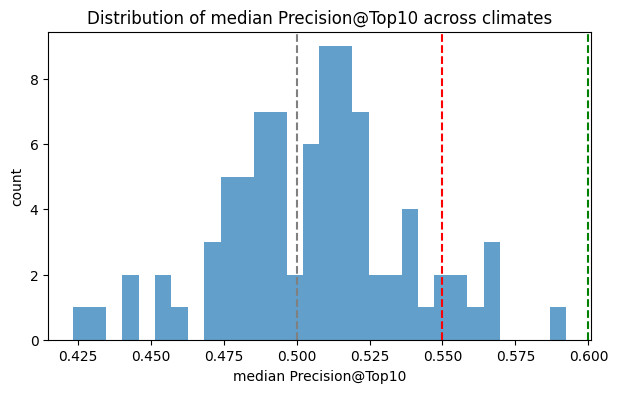

In [ ]:
import matplotlib.pyplot as plt

x = agg["median_precision"].dropna()

plt.figure(figsize=(7,4))
plt.hist(x, bins=30, alpha=0.7)
plt.axvline(0.50, color="gray", linestyle="--")
plt.axvline(0.55, color="red", linestyle="--")
plt.axvline(0.60, color="green", linestyle="--")
plt.title("Distribution of median Precision@Top10 across climates")
plt.xlabel("median Precision@Top10")
plt.ylabel("count")
plt.show()

In [ ]:
top = agg.sort_values(
    ["median_precision", "median_ci_low", "median_n_dir"],
    ascending=False
)

top[[
    "climate_state",
    "median_precision",
    "median_ci_low",
    "worst_precision",
    "median_n_dir",
    "pct_folds_fdr",
    "pct_folds_n_ok"
]].head(10)

,climate_state,median_precision,median_ci_low,worst_precision,median_n_dir,pct_folds_fdr,pct_folds_n_ok
99,3_4_4,0.592308,0.531653,0.592308,2605.0,0.25,0.25
67,2_3_2,0.566468,0.492164,0.555556,1740.5,0.00,0.50
28,1_0_3,0.565476,0.489883,0.565476,1686.0,0.00,0.25
71,2_4_1,0.564764,0.485208,0.509091,1515.5,0.25,0.50
109,4_1_4,0.563834,0.506059,0.513382,3113.0,0.25,0.50
83,3_1_3,0.555556,0.482555,0.495413,1381.0,0.00,0.75
124,4_4_4,0.554549,0.494237,0.554124,2897.0,0.00,0.50
94,3_3_4,0.551724,0.487404,0.551724,2320.0,0.00,0.25
7,0_1_2,0.547342,0.465288,0.523256,1457.5,0.00,0.50
91,3_3_1,0.545455,0.452439,0.545455,1105.0,0.00,0.25
